# M13.7 — Pipeline provisional M13.4b (G3aug): Mondrian, test y eventos reales

Predictor **provisional**: `M13_4b_G3aug_s123` (MRDenseNet, dataset G3 `M13_G3_band1024_w16_500k`,
checkpoint `_final.pt`). Este notebook no entrena, no selecciona modelos ni configuraciones.

- **A. Mondrian:** mismo método e hiperparámetros que la selección congelada de M11
  (taxonomía/score, modo de intervalo, nº de bins, α, k, mínimo por bin, jitter, políticas).
  Los cuantiles se **reajustan sólo con cal** de G3 con las predicciones de 4b. No se reutilizan
  cuantiles de M11.
- **B. Test:** sólo evaluación. Nada se ajusta ni se elige aquí. Criterio impreso, fijado antes de
  ejecutar: |cobertura − nominal| ≤ 2 puntos, marginal y por bin cuando n ≥ 500.
- **C. Eventos reales:** misma cohorte, URLs, caché GWOSC y referencia LVK que M11.14, con el
  procesado de G3 (sección 6).
- **D. Resumen JSON** con sello temporal (modo `'x'`).

> **Roles de los datos.** El test se usa **sólo para evaluación** de un modelo provisional.
> **Ni test ni eventos reales intervienen en la elección del modelo** ni de la configuración
> Mondrian (heredada de la selección de M11 en val). LVK es una referencia, no ground truth; los
> intervalos conformales no son posteriores astrofísicos. Conservative es la política principal;
> efficient se guarda como secundaria.

Ejecutar por secciones. Entregado sin ejecutar.

## 1. Imports y rutas

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, json, pickle, hashlib, inspect, re, urllib.request, os
import h5py
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.config import SimulationConfig
from src.processing import SignalProcessor
from src.models import network
from src.models.dataset import normalize_input_per_sample_per_detector_zscore
from src.real_data.catalog import get_event_detector_url
from src.real_data.gwosc_utils import read_gwosc_hdf5_as_pycbc_timeseries
from src.real_data.signal_processing import build_real_input_like_training, event_window_is_available_and_finite
from src.real_data.psd import select_valid_psd_window, estimate_offsource_psd
from src.real_data.inference import predict_real_with_embeddings
from src.real_data.event_runner import classify_failure_reason
from src.conformal.selected_calibrators import fit_selected_calibrators, apply_selected_calibrators
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.evaluation.lvk import add_lvk_comparison_metrics
import scripts.generate_m11_final_G1 as g1
from scripts.m13.generate_m13_G2_band import apply_overrides, config_sha256
from scripts.m13.generate_m13_G3_whitening import load_m13_config

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
DETECTORS = ["H1", "L1", "V1"]
POLICIES = ["conservative", "efficient"]
PRIMARY_POLICY = "conservative"
# Criterio B fijado antes de ver test: |cov - nominal| <= 2 puntos; por bin sólo si n >= 500.
COVERAGE_TOLERANCE = 0.02
MIN_BIN_N_FOR_CRITERION = 500
EXAMPLE_SEED, N_EXAMPLES = 123, 24

TRAIN_CFG_PATH = PROJECT_ROOT / "configs/experiments/m13/train_m13_4b_G3aug_s123.json"
PRED_CFG_PATH = PROJECT_ROOT / "configs/prediction/predict_m13_4b_G3aug_s123_cal_test.json"
GEN_M13_PATH = PROJECT_ROOT / "configs/generation/generate_m13_G3_band1024_w16.json"
train_cfg, pred_cfg = read_json(TRAIN_CFG_PATH), read_json(PRED_CFG_PATH)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID = train_cfg["dataset"]["dataset_id"]
TAG = train_cfg["outputs"]["checkpoint_tag"]
require(pred_cfg["dataset"] == train_cfg["dataset"], "Prediction/train dataset contract differs")
require(DATASET_ID == "M13_G3_band1024_w16_500k" and TAG == "M13_4b_G3aug_s123", "Unexpected model/dataset")

# Same resolution as scripts/predict_cnn_hdf5.py: results/<dataset_id>/<output.file_name>.
PREDICTIONS_PATH = Path(os.path.normpath(DATA_ROOT / "results" / DATASET_ID / pred_cfg["output"]["file_name"]))
require(PREDICTIONS_PATH == DATA_ROOT / "results/M13_3" / TAG / "cal_test_predictions_embeddings.npz",
        f"Unexpected prediction path {PREDICTIONS_PATH}")
checkpoint_candidates = [DATA_ROOT / "models/checkpoints" / DATASET_ID / pred_cfg["prediction"]["checkpoint_file"],
                         DATA_ROOT / "models/checkpoints" / pred_cfg["prediction"]["checkpoint_file"]]
CHECKPOINT = next((p for p in checkpoint_candidates if p.is_file()), checkpoint_candidates[-1])
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                   file_name=train_cfg["dataset"]["dataset_file"])
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                        file_name=train_cfg["dataset"]["split_file"])

# M11 frozen artifacts: method/hyperparameters (A) and descriptive comparisons (B, C).
M11_RESULTS = DATA_ROOT / "results/M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"
M11_TEST_METRICS = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_test_metrics.csv"
M11_REAL_LVK = M11_RESULTS / "real_events/multi_event/lvk_comparison.csv"

# Real-event cohort/reference exactly as M11.14.
M10_DATASET_ID = read_json(PROJECT_ROOT / "configs/experiments/train_500k_M10_inputzscore_resdilated_emb64_d124_bs256_seed123.json")["dataset"]["dataset_id"]
M10_RESULTS = DATA_ROOT / "results" / M10_DATASET_ID / "real_events_m10_500k_lvk_comparison"
EVENT_LIST_PATH = M10_RESULTS / "multi_event_all_catalog_candidates.csv"
HISTORICAL_FAILURES_PATH = M10_RESULTS / "multi_event_all_failed_events.csv"
LVK_PATH = DATA_ROOT / "lvk_references/GWTC-3-confident_detector_frame_reference_error_propagated.csv"
GWOSC_CACHE = DATA_ROOT / "gwosc_cache"

# New, unique run directory; nothing historical is overwritten.
RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_DIR = DATA_ROOT / "results/M13_3" / TAG / "M13_7_pipeline_provisional" / f"run_{RUN_STAMP}"
FIGURE_DIR = OUTPUT_DIR / "figures"

path_rows = [dict(role=r, path=str(p), exists=p.is_file(), required=req) for r, p, req in [
    ("cal/test predictions", PREDICTIONS_PATH, True), ("checkpoint", CHECKPOINT, True),
    ("G3 HDF5", G3_H5, True), ("split", SPLIT_PATH, True), ("G3 generation config", GEN_M13_PATH, True),
    ("M11 selection (val)", M11_SELECTION, True), ("M11 bundle manifest", M11_BUNDLE_MANIFEST, True),
    ("M10/M11 cohort", EVENT_LIST_PATH, True), ("historical exclusions", HISTORICAL_FAILURES_PATH, True),
    ("LVK reference", LVK_PATH, True),
    ("M11 test metrics (descriptive)", M11_TEST_METRICS, False),
    ("M11 real-event LVK comparison (descriptive)", M11_REAL_LVK, False)]]
path_audit = pd.DataFrame(path_rows)
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit[path_audit.required].exists.all(), "Missing required inputs; inspect path table")
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Output:", OUTPUT_DIR)

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


,role,path,exists,required
0,cal/test predictions,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/cal_test_predictions_embeddings.npz,True,True
1,checkpoint,/data/vserrano/cbc_pe_data/models/checkpoints/M13_3/M13_4b_G3aug_s123_final.pt,True,True
2,G3 HDF5,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True,True
3,split,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz,True,True
4,G3 generation config,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/configs/generation/generate_m13_G3_band1024_w16.json,True,True
5,M11 selection (val),/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/mondrian_m11_selected_from_val.csv,True,True
6,M11 bundle manifest,/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/mondrian_m11_selected_calibrators_frozen_provenance.json,True,True
7,M10/M11 cohort,/data/vserrano/cbc_pe_data/results/bbh_processed_4s_seobnrv4opt_snr10-25_n500_000/real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv,True,True
8,historical exclusions,/data/vserrano/cbc_pe_data/results/bbh_processed_4s_seobnrv4opt_snr10-25_n500_000/real_events_m10_500k_lvk_comparison/multi_event_all_failed_events.csv,True,True
9,LVK reference,/data/vserrano/cbc_pe_data/lvk_references/GWTC-3-confident_detector_frame_reference_error_propagated.csv,True,True


Output: /data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z


## 2. Contratos del predictor y de las predicciones cal/test

`predict_cnn_hdf5.py` guarda `pred_/emb_/y_/idx_` por split, en espacio estandarizado con el
scaler train-only, e `idx_` ordenado. Se verifica la identidad del checkpoint, el dataset, el split,
el scaler y la normalización de entrada, y que la membresía cal/test coincide con el split congelado
de M11 G1.

In [2]:
with np.load(PREDICTIONS_PATH, allow_pickle=True) as z:
    require(set(z["available_splits"].tolist()) == {"cal", "test"}, "Expected cal+test NPZ")
    require(z["label_names"].tolist() == LABELS, "Label order")
    prediction_provenance = {k: z[k].item() for k in
        ("checkpoint_file", "dataset_path", "split_path", "label_stats_path", "model_config", "input_normalization")}
    y_mean, y_std = np.asarray(z["y_mean"], dtype=float), np.asarray(z["y_std"], dtype=float)
    SPLITS = {s: dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                      y=np.asarray(z[f"y_{s}"], dtype=float), emb=np.asarray(z[f"emb_{s}"], dtype=float))
              for s in ("cal", "test")}
require(Path(prediction_provenance["checkpoint_file"]).name == CHECKPOINT.name, "Checkpoint identity")
require(Path(prediction_provenance["dataset_path"]).name == G3_H5.name, "Dataset identity")
require(Path(prediction_provenance["split_path"]).name == SPLIT_PATH.name, "Split identity")
require(prediction_provenance["input_normalization"] == train_cfg["input_normalization"], "Input contract")
require(prediction_provenance["model_config"]["class_name"] == train_cfg["model"]["class_name"], "Model class")
EMB_DIM = int(train_cfg["model"]["kwargs"]["embedding_dim"])
require(y_mean.shape == y_std.shape == (3,) and np.isfinite(y_mean).all() and (y_std > 0).all(), "Scaler")
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: z[f"{s}_idx"] for s in ("train", "val", "cal", "test")}
for s, d in SPLITS.items():
    n = len(split_indices[s])
    require(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"Indices {s}")
    # Prediction NPZ stores sorted physical IDs; compare membership only, keep array order.
    require(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"Split membership {s}")
    for name, width in [("pred", 3), ("y", 3), ("emb", EMB_DIM)]:
        require(d[name].shape == (n, width) and np.isfinite(d[name]).all(), f"Invalid {name}_{s}")
require(np.intersect1d(SPLITS["cal"]["idx"], SPLITS["test"]["idx"]).size == 0, "cal/test overlap")
pred_cal, y_cal, emb_cal = SPLITS["cal"]["pred"], SPLITS["cal"]["y"], SPLITS["cal"]["emb"]
pred_test, y_test, emb_test, idx_test = (SPLITS["test"][k] for k in ("pred", "y", "emb", "idx"))
y_test_phys, pred_test_phys = y_test * y_std + y_mean, pred_test * y_std + y_mean
print(json.dumps({k: (v if k != "model_config" else v["class_name"]) for k, v in prediction_provenance.items()},
                 indent=2, default=str))
display(pd.DataFrame({"label": LABELS, "train_y_mean": y_mean, "train_y_std": y_std}))

{
  "checkpoint_file": "/data/vserrano/cbc_pe_data/models/checkpoints/M13_3/M13_4b_G3aug_s123_final.pt",
  "dataset_path": "/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5",
  "split_path": "/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz",
  "label_stats_path": "/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/M11_final_G1_500k_label_stats_train_only_train400000_val40000_cal30000_test30000_seed123.npz",
  "model_config": "MRDenseNet",
  "input_normalization": {
    "enabled": false,
    "already_normalized": true,
    "mode": "per_sample_per_detector_zscore",
    "eps": 1e-06
  }
}


,label,train_y_mean,train_y_std
0,chirp_mass,37.463547,16.508060
1,total_mass,94.985977,34.703293
2,chi_eff,-0.000219,0.440338


## 3. A — Mondrian: método congelado de M11, cuantiles reajustados sólo con cal (G3, 4b)

Cada uno de los seis sistemas (política × label) toma de la selección M11 en val
(`mondrian_m11_selected_from_val.csv`) su taxonomía (score de binning: predicción o dificultad kNN
sobre embeddings), su modo de intervalo y su número de bins. α, k, el mínimo por bin y el jitter
se leen del manifest del bundle congelado de M11. El ajuste reproduce `scripts/freeze_selected_mondrian.py`:
una llamada `fit_selected_calibrators` por fila, **sólo con cal**, sin grid, sin reselección y sin
reintentos. El bundle se serializa antes de tocar test, así que sólo contiene estado derivado de cal.

El jitter de los bordes (±1e-10) usa un RNG sin semilla, igual que M11 (`jitter_seed=None`). El
pickle guardado fija los sistemas usados en B y C.

In [3]:
m11_manifest = read_json(M11_BUNDLE_MANIFEST)
require(m11_manifest["accepted"] and m11_manifest["failed_checks"] == 0, "M11 bundle not accepted")
m11_meta = m11_manifest["metadata"]
require(m11_meta["fit_split"] == "cal" and m11_meta["selection_split"] == "val"
        and m11_meta["calibration_space"] == "standardized" and m11_meta["label_names"] == LABELS,
        "M11 conformal split/space contract")
require(file_sha256(M11_SELECTION) == m11_meta["selection_sha256"], "M11 selection CSV differs from frozen bundle")
HP = {k: m11_meta[k] for k in ("confidence_level", "n_neighbors", "min_samples_per_bin",
                               "apply_jitter", "jitter_variation")}
# Same constants enforced by freeze_selected_mondrian.py for M11.
require(HP == dict(confidence_level=.9, n_neighbors=5, min_samples_per_bin=20,
                   apply_jitter=True, jitter_variation=1e-10), f"Unexpected M11 hyperparameters {HP}")
NOMINAL = float(HP["confidence_level"])

selection = pd.read_csv(M11_SELECTION)
require(selection.selection_split.eq("val").all(), "M11 selection must come from val")
selected = selection[selection.selection_status == "selected"].copy()
require(set(zip(selected.final_policy, selected.label)) == {(p, l) for p in POLICIES for l in LABELS},
        "Expected six selected M11 systems")
frozen_systems = pd.DataFrame(m11_manifest["systems"])
check = selected.merge(frozen_systems, on=["final_policy", "label"], suffixes=("", "_frozen"), validate="one_to_one")
for key in ("taxonomy_mode", "interval_mode", "n_bins"):
    require((check[key] == check[f"{key}_frozen"]).all(), f"Selection/bundle mismatch {key}")
display(selected[["final_policy", "label", "label_index", "selection_policy", "taxonomy_mode", "interval_mode", "n_bins"]])

calibrators = {}
for _, row in selected.iterrows():
    print(f"fit cal only {row.final_policy}/{row.label}: {row.taxonomy_mode}/{row.interval_mode}/{int(row.n_bins)}")
    calibrators.update(fit_selected_calibrators(pd.DataFrame([row]), pred_cal, y_cal, LABELS,
        emb_cal=emb_cal, **HP))

BUNDLE_PATH = OUTPUT_DIR / "mondrian_m13_7_4b_calibrators_cal_only.pkl"
bundle_metadata = dict(model=TAG, dataset_id=DATASET_ID, label_names=LABELS, y_mean=y_mean.tolist(),
    y_std=y_std.tolist(), calibration_space="standardized", fit_split="cal",
    method_source="M11 frozen selection (val) and hyperparameters; quantiles refit on G3/4b cal",
    m11_selection_path=str(M11_SELECTION), m11_selection_sha256=m11_meta["selection_sha256"],
    checkpoint_path=str(CHECKPOINT), predictions_path=str(PREDICTIONS_PATH), **HP, jitter_seed=None,
    created_utc=datetime.now(timezone.utc).isoformat())
# Serialized before test is touched: cal-derived state only.
with BUNDLE_PATH.open("xb") as f:
    pickle.dump(dict(metadata=bundle_metadata, calibrators=calibrators), f, protocol=4)
BUNDLE_SHA256 = file_sha256(BUNDLE_PATH)
print("Bundle:", BUNDLE_PATH, BUNDLE_SHA256)

,final_policy,label,label_index,selection_policy,taxonomy_mode,interval_mode,n_bins
0,conservative,chirp_mass,0,conservative_zero_under_bins_2sigma,difficulty,asymmetric,16
1,efficient,chirp_mass,0,efficient_local_validity_tolerant,difficulty,asymmetric,48
2,conservative,total_mass,1,conservative_zero_under_bins_2sigma,prediction,asymmetric,4
3,efficient,total_mass,1,efficient_local_validity_tolerant,prediction,asymmetric,4
4,conservative,chi_eff,2,conservative_zero_under_bins_2sigma,difficulty,symmetric,8
5,efficient,chi_eff,2,efficient_local_validity_tolerant,difficulty,symmetric,4


fit cal only conservative/chirp_mass: difficulty/asymmetric/16
fit cal only efficient/chirp_mass: difficulty/asymmetric/48
fit cal only conservative/total_mass: prediction/asymmetric/4
fit cal only efficient/total_mass: prediction/asymmetric/4
fit cal only conservative/chi_eff: difficulty/symmetric/8
fit cal only efficient/chi_eff: difficulty/symmetric/4
Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/mondrian_m13_7_4b_calibrators_cal_only.pkl d785a7652eb7b6f1eba7b68a3030e9ebf120eab2b4c1b8a7d430d8e47309dbf6


## 4. B — Test: cobertura marginal y por bin, anchura (sólo evaluación)

Se aplican los seis sistemas ya serializados, sin reajustar ni elegir nada. Para cada (política, label)
se dan la cobertura marginal, la cobertura por bin con su n y la anchura física media y mediana. El
criterio impreso es |cov − nominal| ≤ 0.02 marginal y en cada bin con n ≥ 500. Los bins con n < 500
se muestran pero no se evalúan. El criterio es un umbral operativo, no un test estadístico.
La comparación con M11 (artefactos de test del bundle congelado) es **descriptiva**: otro predictor,
otro dataset de entrenamiento y otros cuantiles.

In [4]:
test_rows, bin_rows, test_results = [], [], {}
for (policy, label), system in sorted(calibrators.items()):
    j = system.label_index
    # Copy the difficulty model so test application cannot mutate the serialized systems.
    fitted = replace(system.fitted, difficulty_model=copy(system.fitted.difficulty_model))
    prediction = apply_mondrian(fitted, pred_target=pred_test,
        target_embedding=emb_test if system.taxonomy_mode == "difficulty" else None)
    single = MondrianPrediction(lower=prediction.lower[:, j:j+1], upper=prediction.upper[:, j:j+1],
        bin_indices=prediction.bin_indices[:, j:j+1], binning_scores=prediction.binning_scores[:, j:j+1])
    metrics = evaluate_mondrian(fitted, single, y_test[:, j:j+1], tolerance_sigmas=(1, 2, 3))
    width_phys = (single.upper - single.lower)[:, 0] * y_std[j]
    coverage_bins = metrics["coverage_per_bin"][:, 0]
    counts_bins = metrics["counts_per_bin"][:, 0].astype(int)
    assessed = counts_bins >= MIN_BIN_N_FOR_CRITERION
    gaps = np.abs(coverage_bins - NOMINAL)
    coverage = float(metrics["global_coverage"][0])
    marginal_pass = abs(coverage - NOMINAL) <= COVERAGE_TOLERANCE
    bins_fail = int((assessed & (gaps > COVERAGE_TOLERANCE)).sum())
    test_results[(policy, label)] = dict(system=system, j=j, prediction=single, metrics=metrics, width_phys=width_phys)
    test_rows.append(dict(final_policy=policy, label=label, taxonomy_mode=system.taxonomy_mode,
        interval_mode=system.interval_mode, n_bins=system.n_bins, n_test=len(width_phys),
        coverage=coverage, coverage_gap_points=100 * (coverage - NOMINAL), marginal_pass=marginal_pass,
        n_bins_assessed=int(assessed.sum()), n_bins_fail=bins_fail,
        min_bin_coverage_assessed=float(coverage_bins[assessed].min()) if assessed.any() else np.nan,
        max_bin_coverage_assessed=float(coverage_bins[assessed].max()) if assessed.any() else np.nan,
        min_bin_n=int(counts_bins.min()), bins_pass=bins_fail == 0,
        mean_width_phys=float(width_phys.mean()), median_width_phys=float(np.median(width_phys)),
        lower_miss_rate=float(np.mean(y_test[:, j] < single.lower[:, 0])),
        upper_miss_rate=float(np.mean(y_test[:, j] > single.upper[:, 0]))))
    for b, (cov, n) in enumerate(zip(coverage_bins, counts_bins)):
        bin_rows.append(dict(final_policy=policy, label=label, mondrian_bin=b, n=int(n), coverage=float(cov),
            assessed=bool(n >= MIN_BIN_N_FOR_CRITERION),
            within_2_points=bool(abs(cov - NOMINAL) <= COVERAGE_TOLERANCE) if n > 0 else np.nan,
            median_width_phys=float(np.median(width_phys[single.bin_indices[:, 0] == b])) if n > 0 else np.nan))
test_summary = pd.DataFrame(test_rows)
test_bins = pd.DataFrame(bin_rows)
display(test_summary)
with pd.option_context("display.max_rows", 400):
    display(test_bins)
print(f"CRITERION (fixed before test): |coverage - {NOMINAL:.2f}| <= {COVERAGE_TOLERANCE:.2f}; "
      f"per bin only if n >= {MIN_BIN_N_FOR_CRITERION}")
for r in test_summary.itertuples():
    print(f"  {r.final_policy:12s} {r.label:10s} marginal {r.coverage:.4f} "
          f"[{'PASS' if r.marginal_pass else 'FAIL'}]  bins {r.n_bins_assessed - r.n_bins_fail}/{r.n_bins_assessed} "
          f"within [{'PASS' if r.bins_pass else 'FAIL'}]")
test_summary.to_csv(OUTPUT_DIR / "test_coverage_summary.csv", index=False)
test_bins.to_csv(OUTPUT_DIR / "test_coverage_per_bin.csv", index=False)

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,30000,0.903000,0.300000,True,8,0,0.899431,0.908874,3606,True,0.509585,0.490458,0.051833,0.045167
1,conservative,chirp_mass,difficulty,asymmetric,16,30000,0.899567,-0.043333,True,16,1,0.879619,0.919577,1786,False,13.273516,13.218064,0.051467,0.048967
2,conservative,total_mass,prediction,asymmetric,4,30000,0.904433,0.443333,True,4,0,0.895643,0.913296,7393,True,25.735062,22.824977,0.046500,0.049067
3,efficient,chi_eff,difficulty,symmetric,4,30000,0.905067,0.506667,True,4,0,0.902676,0.908167,7213,True,0.512877,0.475694,0.050300,0.044633
4,efficient,chirp_mass,difficulty,asymmetric,48,30000,0.897533,-0.246667,True,48,11,0.851852,0.939641,529,False,13.204895,13.209014,0.052233,0.050233
5,efficient,total_mass,prediction,asymmetric,4,30000,0.904433,0.443333,True,4,0,0.895643,0.913296,7393,True,25.735062,22.824977,0.046500,0.049067


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,3911,0.900537,True,True,0.372317
1,conservative,chi_eff,1,3734,0.904392,True,True,0.421643
2,conservative,chi_eff,2,3902,0.900564,True,True,0.456722
3,conservative,chi_eff,3,3775,0.908874,True,True,0.490458
4,conservative,chi_eff,4,3689,0.899431,True,True,0.499786
5,conservative,chi_eff,5,3776,0.908104,True,True,0.552360
6,conservative,chi_eff,6,3607,0.899917,True,True,0.600020
7,conservative,chi_eff,7,3606,0.902108,True,True,0.701529
8,conservative,chirp_mass,0,1890,0.919577,True,True,1.819386
9,conservative,chirp_mass,1,1885,0.894960,True,True,2.795077


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9030 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.8996 [PASS]  bins 15/16 within [FAIL]
  conservative total_mass marginal 0.9044 [PASS]  bins 4/4 within [PASS]
  efficient    chi_eff    marginal 0.9051 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.8975 [PASS]  bins 37/48 within [FAIL]
  efficient    total_mass marginal 0.9044 [PASS]  bins 4/4 within [PASS]


In [5]:
# Descriptive comparison with M11 frozen test artifacts (different predictor and quantiles).
if M11_TEST_METRICS.is_file():
    m11_test = pd.read_csv(M11_TEST_METRICS)
    m11_test = m11_test[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins",
                         "global_coverage", "global_mean_width_phys", "global_median_width_phys"]].rename(
        columns={"global_coverage": "coverage_M11", "global_mean_width_phys": "mean_width_phys_M11",
                 "global_median_width_phys": "median_width_phys_M11"})
    width_comparison = test_summary[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins",
                                     "coverage", "mean_width_phys", "median_width_phys"]].merge(
        m11_test, on=["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins"], validate="one_to_one")
    require(len(width_comparison) == 6, "M11 test metrics do not match the six inherited systems")
    width_comparison["mean_width_ratio_vs_M11"] = width_comparison.mean_width_phys / width_comparison.mean_width_phys_M11
    display(width_comparison)
    width_comparison.to_csv(OUTPUT_DIR / "test_width_vs_M11_descriptive.csv", index=False)
else:
    width_comparison = None
    print("M11 test metrics not found; descriptive comparison omitted:", M11_TEST_METRICS)

,final_policy,label,taxonomy_mode,interval_mode,n_bins,coverage,mean_width_phys,median_width_phys,coverage_M11,mean_width_phys_M11,median_width_phys_M11,mean_width_ratio_vs_M11
0,conservative,chi_eff,difficulty,symmetric,8,0.903000,0.509585,0.490458,0.905233,0.615966,0.608739,0.827295
1,conservative,chirp_mass,difficulty,asymmetric,16,0.899567,13.273516,13.218064,0.902500,16.689815,15.002292,0.795306
2,conservative,total_mass,prediction,asymmetric,4,0.904433,25.735062,22.824977,0.906667,30.709322,27.696938,0.838021
3,efficient,chi_eff,difficulty,symmetric,4,0.905067,0.512877,0.475694,0.907100,0.619959,0.623795,0.827276
4,efficient,chirp_mass,difficulty,asymmetric,48,0.897533,13.204895,13.209014,0.901600,16.623365,15.552326,0.794358
5,efficient,total_mass,prediction,asymmetric,4,0.904433,25.735062,22.824977,0.906667,30.709322,27.696938,0.838021


## 5. B — Figuras de adaptabilidad (test, conservative)

La anchura física se muestra por bin de Mondrian y frente al SNR de red final y a los valores
verdaderos de M_total y χ_eff, con hexbin y la mediana por cuantiles de la variable. El SNR es
`final_network_snr` del HDF5 de G3 (banda 30–1024 Hz) y se lee preservando el orden de `idx_test`. Se
muestra además una selección fija de ejemplos de test (semilla 123): predicción, intervalo y valor
verdadero.

In [6]:
def read_hdf5_dataset_preserve_order(h5_file, dataset_key, indices):
    indices = np.asarray(indices, dtype=np.int64)
    order = np.argsort(indices, kind="stable")
    values_sorted = np.asarray(h5_file[dataset_key][indices[order]])
    inverse = np.empty_like(order)
    inverse[order] = np.arange(len(order))
    return values_sorted[inverse]

with h5py.File(G3_H5, "r") as h:
    require(h.attrs.get("experiment_id") == DATASET_ID, "HDF5 from another dataset")
    require("final_network_snr" in h, "final_network_snr missing in G3 HDF5")
    test_snr = read_hdf5_dataset_preserve_order(h, "final_network_snr", idx_test).astype(float)
require(np.isfinite(test_snr).all(), "Non-finite SNR")

LABEL_TEX = {"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_{\mathrm{eff}}$"}
LABEL_UNIT = {"chirp_mass": r"$M_\odot$", "total_mass": r"$M_\odot$", "chi_eff": ""}
def width_ylabel(label):
    return f"interval width [{LABEL_UNIT[label]}]" if LABEL_UNIT[label] else "interval width"
def save(fig, name):
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

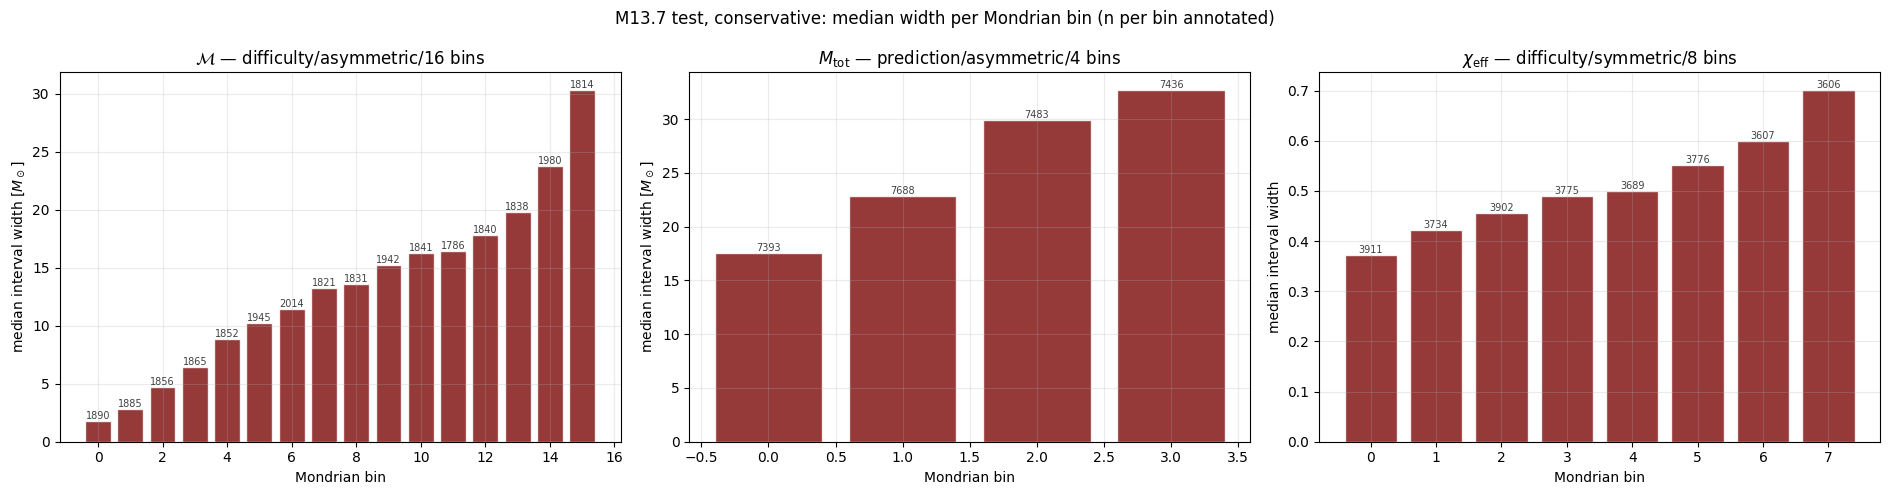

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, label in zip(axes, LABELS):
    r = test_results[(PRIMARY_POLICY, label)]
    table = test_bins[(test_bins.final_policy == PRIMARY_POLICY) & (test_bins.label == label)]
    ax.bar(table.mondrian_bin, table.median_width_phys, color="#831616", alpha=.85, edgecolor="white")
    for b, w, n in zip(table.mondrian_bin, table.median_width_phys, table.n):
        if np.isfinite(w):
            ax.text(b, w, str(n), ha="center", va="bottom", fontsize=7, color="0.25")
    s = r["system"]
    ax.set(title=f"{LABEL_TEX[label]} — {s.taxonomy_mode}/{s.interval_mode}/{s.n_bins} bins",
           xlabel="Mondrian bin", ylabel="median " + width_ylabel(label))
    ax.grid(alpha=.25)
fig.suptitle(f"M13.7 test, {PRIMARY_POLICY}: median width per Mondrian bin (n per bin annotated)")
fig.tight_layout()
save(fig, "test_width_per_mondrian_bin")

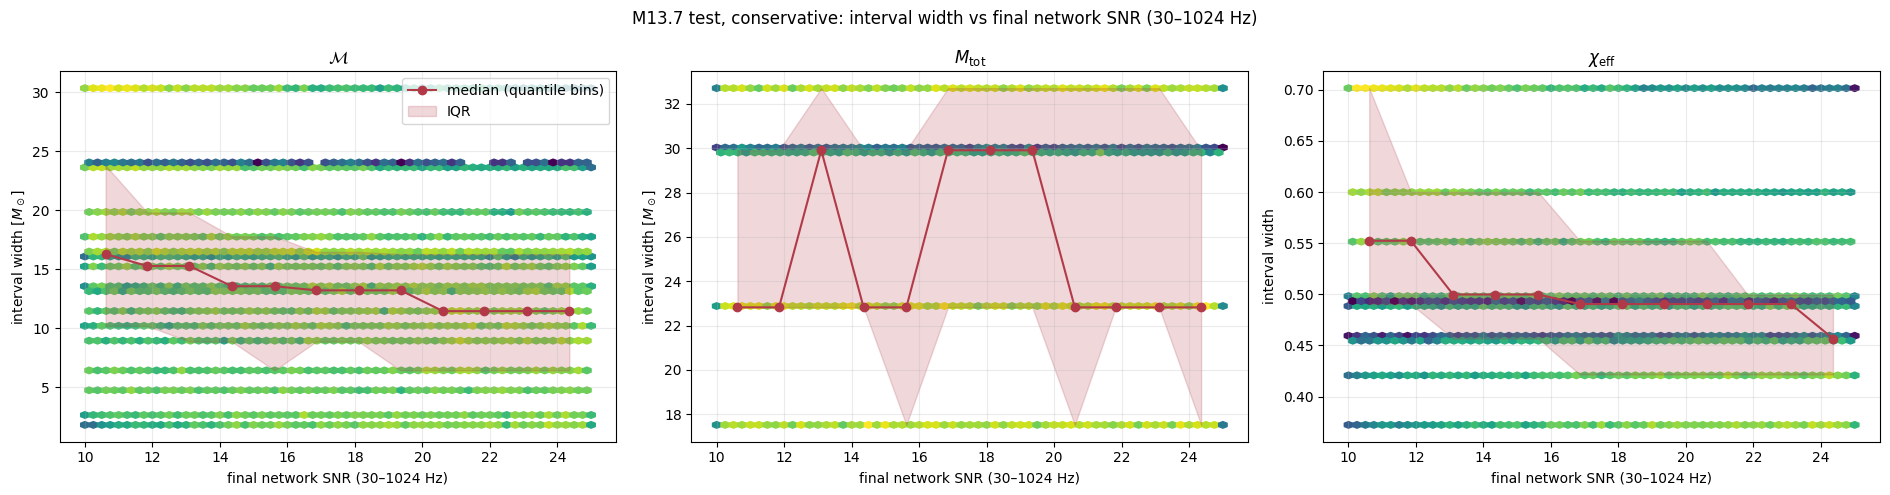

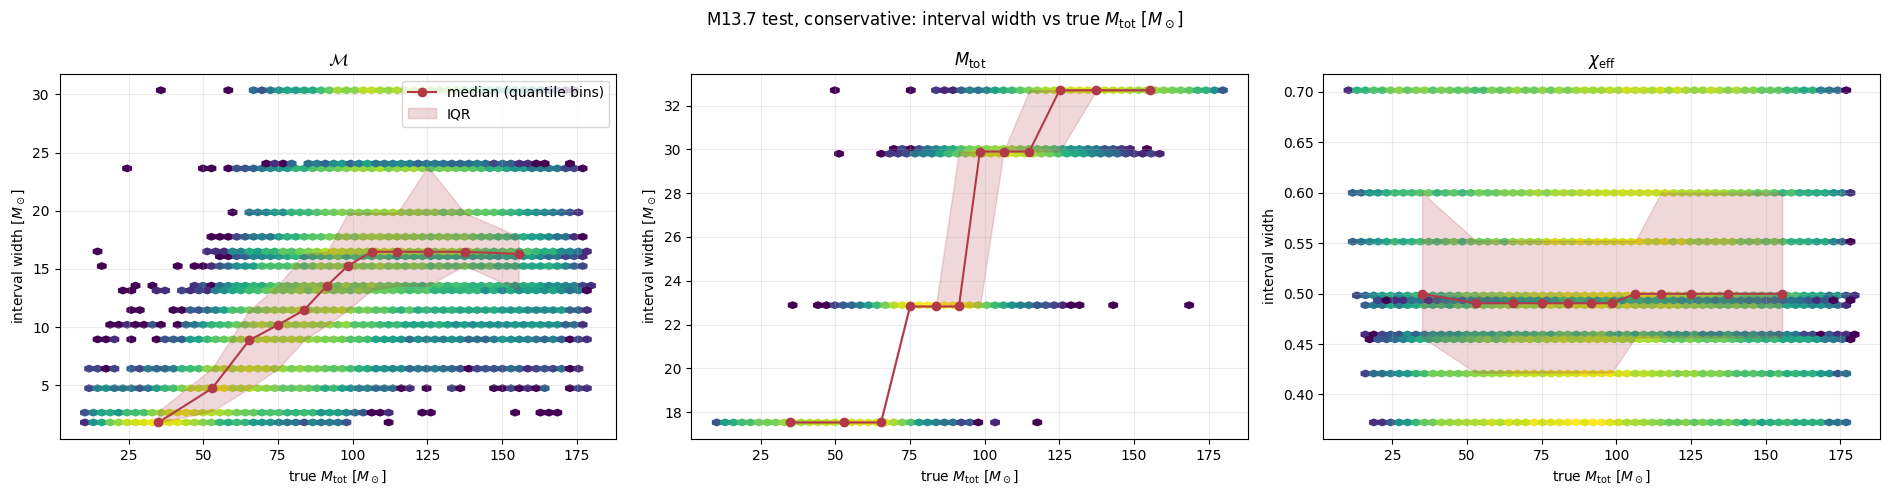

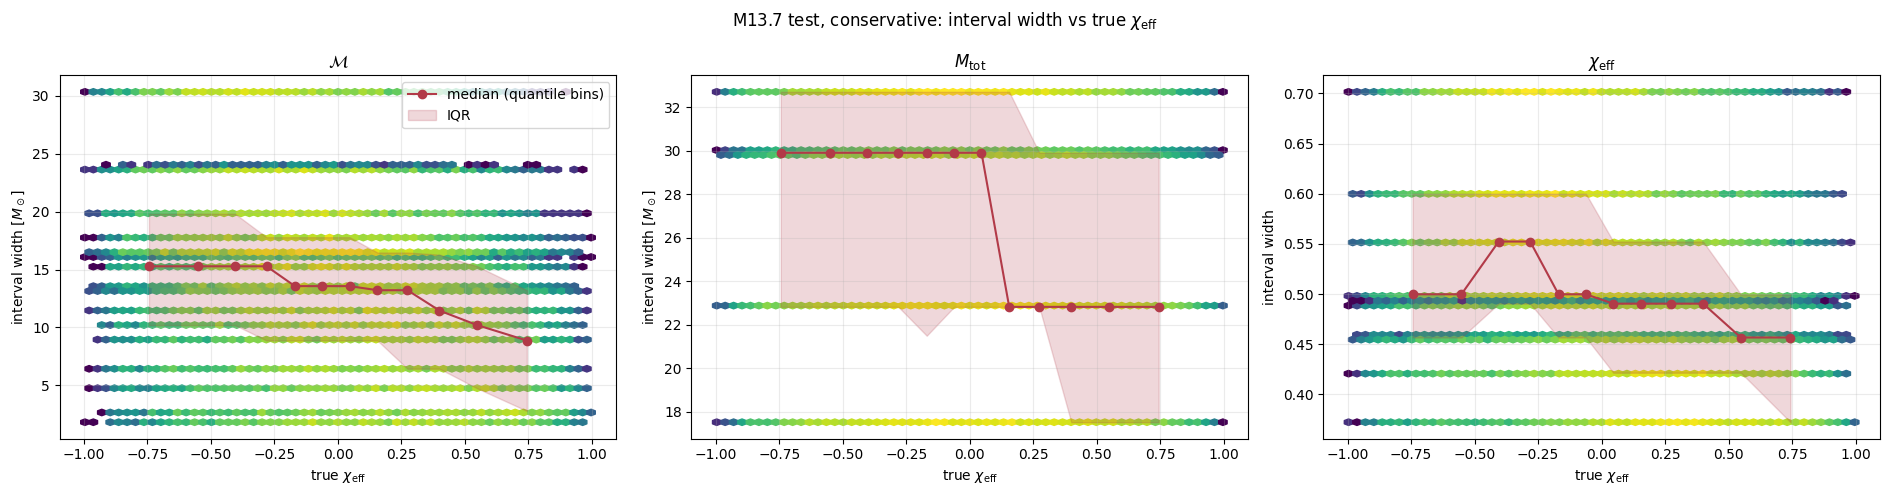

In [8]:
def plot_width_vs(x, xlabel, name, n_quantile_bins=12):
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_quantile_bins + 1)))
    which = np.clip(np.digitize(x, edges[1:-1]), 0, len(edges) - 2)
    centers = np.array([np.median(x[which == k]) for k in range(len(edges) - 1)])
    for ax, label in zip(axes, LABELS):
        w = test_results[(PRIMARY_POLICY, label)]["width_phys"]
        ax.hexbin(x, w, gridsize=60, bins="log", mincnt=1, cmap="viridis")
        q = np.array([np.quantile(w[which == k], [.25, .5, .75]) for k in range(len(edges) - 1)])
        ax.plot(centers, q[:, 1], "o-", color="#B23A48", label="median (quantile bins)")
        ax.fill_between(centers, q[:, 0], q[:, 2], color="#B23A48", alpha=.2, label="IQR")
        ax.set(title=LABEL_TEX[label], xlabel=xlabel, ylabel=width_ylabel(label))
        ax.grid(alpha=.25)
    axes[0].legend()
    fig.suptitle(f"M13.7 test, {PRIMARY_POLICY}: interval width vs {xlabel}")
    fig.tight_layout()
    save(fig, name)

plot_width_vs(test_snr, r"final network SNR (30–1024 Hz)", "test_width_vs_snr")
plot_width_vs(y_test_phys[:, LABELS.index("total_mass")], r"true $M_{\mathrm{tot}}$ [$M_\odot$]", "test_width_vs_true_total_mass")
plot_width_vs(y_test_phys[:, LABELS.index("chi_eff")], r"true $\chi_{\mathrm{eff}}$", "test_width_vs_true_chi_eff")

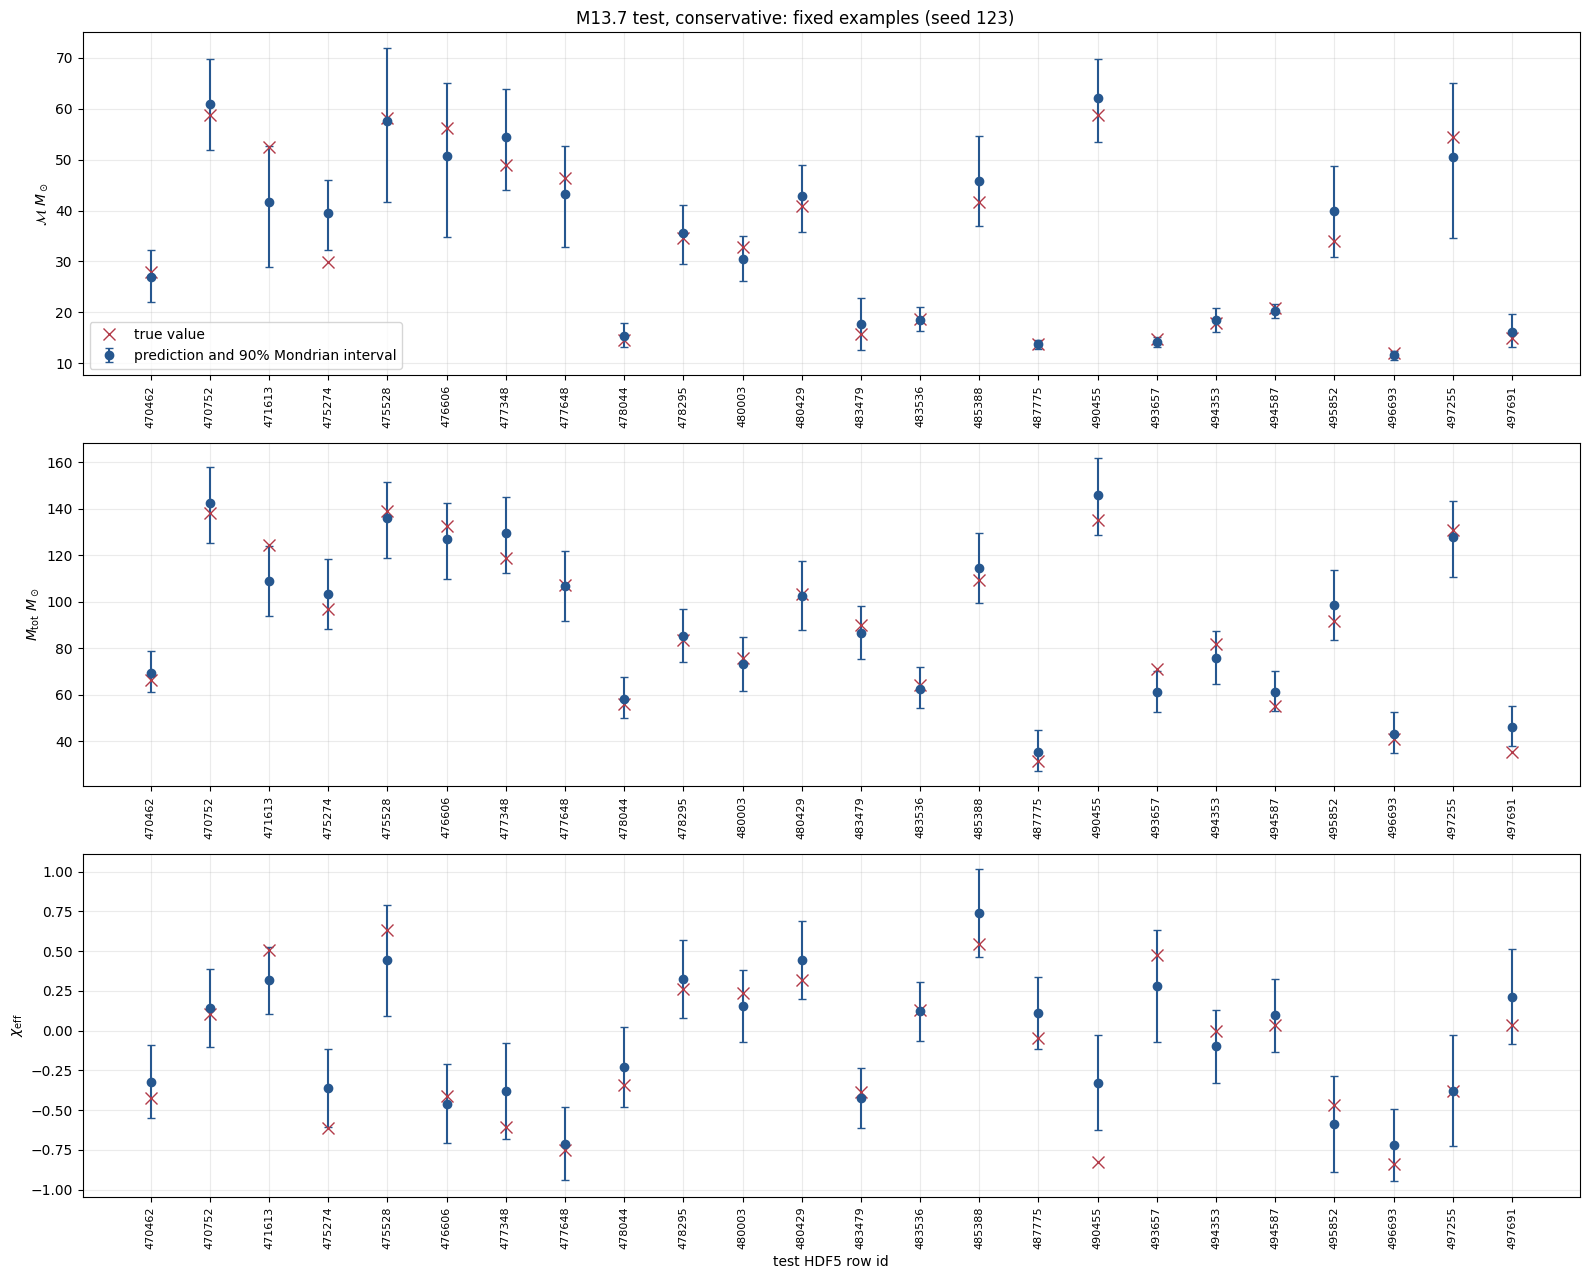

In [9]:
# Fixed example selection (seed fixed before looking at results); positions in the NPZ test order.
example_pos = np.sort(np.random.default_rng(EXAMPLE_SEED).choice(len(idx_test), size=N_EXAMPLES, replace=False))
example_rows = []
fig, axes = plt.subplots(3, 1, figsize=(16, 13))
for ax, label in zip(axes, LABELS):
    r = test_results[(PRIMARY_POLICY, label)]
    j = r["j"]
    lower = r["prediction"].lower[example_pos, 0] * y_std[j] + y_mean[j]
    upper = r["prediction"].upper[example_pos, 0] * y_std[j] + y_mean[j]
    pred, true = pred_test_phys[example_pos, j], y_test_phys[example_pos, j]
    x = np.arange(N_EXAMPLES)
    ax.errorbar(x, pred, yerr=[pred - lower, upper - pred], fmt="o", color="#26578F", capsize=3,
                label=f"prediction and {int(100 * NOMINAL)}% Mondrian interval")
    ax.plot(x, true, "x", color="#B23A48", markersize=8, label="true value")
    ax.set_xticks(x)
    ax.set_xticklabels(idx_test[example_pos], rotation=90, fontsize=8)
    ax.set(ylabel=f"{LABEL_TEX[label]} {LABEL_UNIT[label]}")
    ax.grid(alpha=.25)
    example_rows += [dict(hdf5_row=int(idx_test[p]), label=label, prediction=float(a), lower=float(lo),
                          upper=float(up), true=float(t), covered=bool(lo <= t <= up), network_snr=float(test_snr[p]))
                     for p, a, lo, up, t in zip(example_pos, pred, lower, upper, true)]
axes[0].legend()
axes[-1].set_xlabel("test HDF5 row id")
fig.suptitle(f"M13.7 test, {PRIMARY_POLICY}: fixed examples (seed {EXAMPLE_SEED})")
fig.tight_layout()
save(fig, "test_fixed_examples")
test_examples = pd.DataFrame(example_rows)
test_examples.to_csv(OUTPUT_DIR / "test_fixed_examples.csv", index=False)

## 6. C — Procesado real con el contrato G3

**Construcción.** Se sigue la misma lógica que `scripts/m13/generate_m13_G3_whitening.py`:
`load_m13_config(generate_m13_G3_band1024_w16.json)`, `config_json` del HDF5 G1 base (con su hash),
`apply_overrides` → `spec_g3`, `SimulationConfig(**spec_g3["simulation"])` y
`SignalProcessor(config, **spec_g3["signal_processor"])`. De ahí salen el contexto 33408/33408, la
longitud de procesado (16384 + 2·33408 = 83200), `processing_delta_f` y `processing_flength`, y el
filtro de whitening de 16 s con lowpass a 1024 Hz. Con `assert` se comprueba que coinciden con los
atributos `config_json` y `processing_configuration` del HDF5 de G3, y se repiten las comprobaciones
de `check_physics` (crop_to_config y que el contexto cubra el margen corrompido).

**Equivalencia de la PSD con G3.** En G1/G3 (`estimate_raw_offsource_psd`), la PSD sale de Welch
con segmentos de 8 s, se interpola a `processing_delta_f` y se recorta a `processing_flength`, **sin**
truncado del espectro inverso. `SignalProcessor` la acondiciona **una sola vez** al blanquear
(`inverse_spectrum_truncation` de 16 s, Hann). Aquí se usa `psd_max_filter_duration=None`: la estimación real no trunca y
el procesador trunca una vez a 16 s, igual que en G3. Antes de procesar se comprueba que la llamada
de Welch no lleva argumentos explícitos en ninguno de los dos códigos (mismo solapamiento, ventana y
promedio por defecto de PyCBC) y que la interpolación es `pycbc.psd.interpolate` en ambos. En cada
evento y detector se comprueba además que la PSD real es **idéntica bit a bit** a la que devuelve
`estimate_raw_offsource_psd` de G1 sobre la misma ventana. Si alguna comprobación falla, el notebook se detiene.

**Diferencia con M11.** M11.14 acondicionaba dos veces (0,5 s en la estimación y 0,5 s en
`SignalProcessor`), frente a una sola vez en G1. Esa diferencia se aceptó en M11.14 como
"acondicionamiento PSD histórico" y **no se midió**. M13.7 no la hereda.

Se mantiene sin cambios la política nominal de M11.14: ventana PSD (−1024, −640) s, centro = GPS + 0,
sin ventanas alternativas y z-score una sola vez (ε = 1e−6). Las ventanas PSD de entrenamiento venían
de bloques off-source del manifest G1. Esa política no se toca aquí.

In [10]:
m13_gen = load_m13_config(GEN_M13_PATH)
g1_path = DATA_ROOT / "processed" / m13_gen["base_g1_h5"]
require(g1_path.is_file(), f"Base G1 HDF5 missing: {g1_path}")
with h5py.File(g1_path, "r") as h:
    spec_g1 = json.loads(h.attrs["config_json"])
    require(config_sha256(spec_g1) == h.attrs["config_sha256"], "G1 config_json/config_sha256 mismatch")
spec_g3 = apply_overrides(spec_g1, m13_gen["overrides"])
sim, sp = spec_g3["simulation"], spec_g3["signal_processor"]
sim_config = SimulationConfig(**sim)
processor = SignalProcessor(config=sim_config, **sp)

# Same consistency checks as check_physics in generate_m13_G3_whitening.py.
require(sim_config.sampling_frequency == 4096 and sim_config.duration == 4.0 and sim_config.length == 16384,
        "Final window contract")
require(processor.output_mode == "crop_to_config", "Expected output_mode='crop_to_config'")
require(processor.lowpass_frequency == sp["lowpass_frequency"] == 1024.0, "Lowpass")
require(processor.whitening_max_filter_duration == sp["whitening_max_filter_duration"] == 16.0, "Whitening filter")
require(not processor.apply_standardization, "Z-score must be applied once outside the processor")
CTX_START, CTX_END = sim_config.processing_context_start_samples, sim_config.processing_context_end_samples
require((CTX_START, CTX_END) == (33408, 33408), "Context")
margin = processor.corrupted_margin_samples_per_side()
require(CTX_START >= margin and CTX_END >= margin, f"Context < corrupted margin {margin}")

FS = float(sim_config.sampling_frequency)
FINAL_DURATION, FINAL_LENGTH = float(sim_config.duration), int(sim_config.length)
PROCESSING_LENGTH = int(sim_config.processing_length)
PSD_DELTA_F = float(sim_config.processing_delta_f)
PROCESSING_FLENGTH = int(sim_config.processing_flength)
# G3 contract: the estimation does not truncate; SignalProcessor conditions once (16 s).
PSD_MAX_FILTER_DURATION = None
PSD_SEGMENT_DURATION = g1.PSD_SEGMENT_DURATION_S
NOMINAL_PSD, CENTER_OFFSET = (-1024.0, -640.0), 0.0
INPUT_EPS = float(train_cfg["input_normalization"]["eps"])
require(PROCESSING_LENGTH == FINAL_LENGTH + CTX_START + CTX_END == 83200, "processing_length")
require(np.isclose(PSD_DELTA_F, FS / PROCESSING_LENGTH) and PROCESSING_FLENGTH == PROCESSING_LENGTH // 2 + 1,
        "PSD frequency grid")
require(PSD_SEGMENT_DURATION == 8.0 and INPUT_EPS == 1e-6, "Welch segment / z-score eps")

# Compare with the G3 HDF5 attributes written by build_attrs.
expected_processing_configuration = json.dumps({
    "lowpass_frequency_hz": float(sp["lowpass_frequency"]),
    "whitening_max_filter_duration_s": float(sp["whitening_max_filter_duration"]),
    "processing_context_start_samples": int(sim["processing_context_start_samples"]),
    "processing_context_end_samples": int(sim["processing_context_end_samples"]),
    "snr_band_hz": [float(sim["low_frequency_cutoff"]), float(sim["snr_high_frequency_cutoff"])],
    "signal_processor": sp,
}, sort_keys=True)
with h5py.File(G3_H5, "r") as h:
    g3_attrs = {k: h.attrs[k] for k in ("processing_configuration", "config_json",
                                        "corrupted_margin_samples_per_side", "m13_config_json")}
assert g3_attrs["processing_configuration"] == expected_processing_configuration, "processing_configuration differs"
assert json.loads(g3_attrs["config_json"]) == spec_g3, "config_json differs from rebuilt spec_g3"
assert json.loads(g3_attrs["m13_config_json"]) == m13_gen, "m13_config_json differs"
assert int(g3_attrs["corrupted_margin_samples_per_side"]) == margin, "corrupted margin differs"
g3_processing = json.loads(g3_attrs["processing_configuration"])
assert (g3_processing["processing_context_start_samples"], g3_processing["processing_context_end_samples"]) == (CTX_START, CTX_END)
assert g3_processing["whitening_max_filter_duration_s"] == processor.whitening_max_filter_duration

# Welch/interpolation equivalence (source level): both call TimeSeries.psd(segment) with PyCBC
# defaults (50% overlap, Hann window, median averaging) and pycbc.psd.interpolate.
welch_call = re.compile(r"psd_data\.psd\(\s*(float\(\s*)?psd_segment_duration\s*\)?\s*\)")
for name, fn in [("G1/G3 estimate_raw_offsource_psd", g1.estimate_raw_offsource_psd),
                 ("real estimate_offsource_psd", estimate_offsource_psd)]:
    source = inspect.getsource(fn)
    require(len(welch_call.findall(source)) == 1 and source.count(".psd(") == 1,
            f"{name}: Welch call is not the plain default call; STOP")
    require(re.search(r"interpolate\(\s*psd\s*,", source) is not None, f"{name}: interpolation differs; STOP")
from pycbc.psd import interpolate as pycbc_interpolate
import src.real_data.psd as real_psd_module
require(real_psd_module.interpolate is pycbc_interpolate, "Real pipeline interpolation is not pycbc.psd.interpolate")
# g1 binds `interpolate` lazily in initialize_physics (the same pycbc.psd.interpolate object).
if not hasattr(g1, "interpolate"):
    g1.interpolate = pycbc_interpolate
require(g1.interpolate is pycbc_interpolate, "G1 interpolation is not pycbc.psd.interpolate")

# SignalProcessor.metadata() is not used: its legacy usable_duration_after_processing_margins assumes no
# processing context and raises for the 16 s filter (margin 8.15 s > 4 s). With crop_to_config the context
# (33408 samples/side, checked above) covers the corrupted margin, so the processor is recorded by its spec.
processing_contract = dict(processor=dict(signal_processor=sp, output_mode=processor.output_mode,
        corrupted_margin_samples_per_side=int(margin)), context_samples=[CTX_START, CTX_END],
    processing_length=PROCESSING_LENGTH, psd_delta_f=PSD_DELTA_F, processing_flength=PROCESSING_FLENGTH,
    psd_max_filter_duration_in_estimation=PSD_MAX_FILTER_DURATION,
    whitening_max_filter_duration_in_processor=processor.whitening_max_filter_duration,
    psd_segment_duration=PSD_SEGMENT_DURATION, nominal_psd_window=NOMINAL_PSD, center_offset=CENTER_OFFSET,
    zscore_eps=INPUT_EPS, g3_processing_configuration=g3_processing)
print(json.dumps({k: v for k, v in processing_contract.items() if k != "processor"}, indent=2))

{
  "context_samples": [
    33408,
    33408
  ],
  "processing_length": 83200,
  "psd_delta_f": 0.04923076923076923,
  "processing_flength": 41601,
  "psd_max_filter_duration_in_estimation": null,
  "whitening_max_filter_duration_in_processor": 16.0,
  "psd_segment_duration": 8.0,
  "nominal_psd_window": [
    -1024.0,
    -640.0
  ],
  "center_offset": 0.0,
  "zscore_eps": 1e-06,
  "g3_processing_configuration": {
    "lowpass_frequency_hz": 1024.0,
    "processing_context_end_samples": 33408,
    "processing_context_start_samples": 33408,
    "signal_processor": {
      "apply_highpass": true,
      "apply_lowpass": true,
      "apply_standardization": false,
      "fir_beta": 5.0,
      "fir_order": 256,
      "highpass_frequency": 30.0,
      "lowpass_frequency": 1024.0,
      "output_mode": "crop_to_config",
      "remove_corrupted": true,
      "whitening_low_frequency_cutoff": 30.0,
      "whitening_max_filter_duration": 16.0,
      "whitening_method": "psd",
      "whitening_

In [11]:
# Trusted local checkpoint (own training; sha256 recorded in D). It stores numpy scaler arrays, so
# torch>=2.6 needs weights_only=False; PyTorch 1.9.1 (VM) has no weights_only argument.
load_kwargs = {"map_location": "cpu"}
if "weights_only" in inspect.signature(torch.load).parameters:
    load_kwargs["weights_only"] = False
checkpoint = torch.load(CHECKPOINT, **load_kwargs)
model_config = checkpoint["model_config"]
require(model_config["class_name"] == train_cfg["model"]["class_name"]
        and model_config["model_kwargs"] == train_cfg["model"]["kwargs"], "Checkpoint model contract")
require(model_config["input_normalization"] == train_cfg["input_normalization"], "Checkpoint input contract")
require(checkpoint["checkpoint_tag"] == TAG, "Checkpoint tag")
for key, arr in (("y_mean", y_mean), ("y_std", y_std)):
    require(np.array_equal(np.asarray(checkpoint[key], dtype=float), arr), f"Scaler {key} differs from NPZ")
model = getattr(network, model_config["class_name"])(**model_config["model_kwargs"])
model.load_state_dict(checkpoint["model_state_dict"])
model = model.cpu().eval()
del checkpoint
# Real events use exactly the serialized cal-only bundle from section A.
with BUNDLE_PATH.open("rb") as f:
    real_calibrators = pickle.load(f)["calibrators"]
require(set(real_calibrators) == {(p, l) for p in POLICIES for l in LABELS}, "Expected six systems")

events = pd.read_csv(EVENT_LIST_PATH)
require(not events.event.duplicated().any() and len(events) == 14, "M10/M11 frozen cohort changed")
historical_failures = pd.read_csv(HISTORICAL_FAILURES_PATH)
events["historical_failure"] = events.event.map(historical_failures.set_index("event")["error"]).fillna("")
events["processing_status"] = "pending"
lvk_reference = pd.read_csv(LVK_PATH)
require(not lvk_reference.event.duplicated().any(), "Duplicate LVK event reference")
lvk_reference = lvk_reference.set_index("event")
display(events[["event", "gps_time", "detectors", "catalog", "historical_failure"]])

,event,gps_time,detectors,catalog,historical_failure
0,GW200202_154313,1.264693e+09,"H1,L1,V1",GWTC-3-confident,
1,GW191129_134029,1.259070e+09,"H1,L1,V1",GWTC-3-confident,Invalid event window: V1: event processing win...
2,GW200316_215756,1.268431e+09,"H1,L1,V1",GWTC-3-confident,
3,GW200225_060421,1.266646e+09,"H1,L1,V1",GWTC-3-confident,Invalid event window: V1: event processing win...
4,GW191215_223052,1.260484e+09,"H1,L1,V1",GWTC-3-confident,
5,GW200129_065458,1.264316e+09,"H1,L1,V1",GWTC-3-confident,
6,GW200311_115853,1.267963e+09,"H1,L1,V1",GWTC-3-confident,
7,GW200208_130117,1.265202e+09,"H1,L1,V1",GWTC-3-confident,
8,GW200224_222234,1.266618e+09,"H1,L1,V1",GWTC-3-confident,
9,GW200219_094415,1.266141e+09,"H1,L1,V1",GWTC-3-confident,


### Helpers (cohorte, caché y LVK idénticos a M11.14)

`prepare_nominal` reproduce el de M11.14 (URL de catálogo, búsqueda en las mismas tres rutas de
caché, sin reparar ficheros corruptos y sin ventanas alternativas) con los parámetros G3 de arriba.
`check_psd_equivalence` se ejecuta como etapa propia. Si falla, la ejecución se detiene en lugar
de registrar el evento como excluido.

In [12]:
def prepare_nominal(event, gps, available_detectors, catalog):
    require(set(str(available_detectors).split(",")) >= set(DETECTORS), "missing_required_detectors")
    raw, sources = {}, []
    for detector in DETECTORS:
        url = get_event_detector_url(event_name=event, detector=detector, catalog=catalog, sample_rate=4096)
        require(url is not None, f"missing_url: {event}/{detector}")
        filename = url.rsplit("/", 1)[-1]
        locations = [GWOSC_CACHE / filename, GWOSC_CACHE / "notebooks_root" / filename,
                     GWOSC_CACHE / "m11" / filename]
        local = next((p for p in locations if p.is_file()), locations[0])
        if not local.is_file():
            GWOSC_CACHE.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(url, local)
        strain = read_gwosc_hdf5_as_pycbc_timeseries(local)
        require(float(strain.sample_rate) == FS, f"sample_rate: {detector}")
        raw[detector] = strain
        sources.append(dict(detector=detector, url=url, cached_file=str(local)))
    center = float(gps) + CENTER_OFFSET
    ok, reason = event_window_is_available_and_finite(raw, center, final_duration=FINAL_DURATION,
        context_start_samples=CTX_START, context_end_samples=CTX_END, sampling_frequency=FS)
    require(ok, f"Invalid event window: {reason}")
    selected_window = select_valid_psd_window(raw, center, preferred_window=NOMINAL_PSD, candidate_windows=())
    X_pre, _, psds, _, meta = build_real_input_like_training(raw_strains=raw, detectors=DETECTORS,
        center_time=center, processor=processor, expected_detector_order=DETECTORS,
        final_duration=FINAL_DURATION, final_length=FINAL_LENGTH, processing_length=PROCESSING_LENGTH,
        context_start_samples=CTX_START, context_end_samples=CTX_END, sampling_frequency=FS,
        psd_delta_f=PSD_DELTA_F, psd_target_flength=PROCESSING_FLENGTH,
        psd_start_offset=selected_window[0], psd_end_offset=selected_window[1],
        psd_segment_duration=PSD_SEGMENT_DURATION, psd_max_filter_duration=PSD_MAX_FILTER_DURATION)
    X = normalize_input_per_sample_per_detector_zscore(X_pre[0], eps=INPUT_EPS)[None, :, :]
    require(X.shape == (1, 3, FINAL_LENGTH) and np.isfinite(X).all(), "Invalid nominal input")
    diagnostics = pd.DataFrame([dict(event=event, detector=detector,
        pre_zscore_std=float(X_pre[0, j].std()),
        pre_zscore_rms=float(np.sqrt(np.mean(X_pre[0, j].astype(float) ** 2))),
        post_zscore_mean=float(X[0, j].mean()), post_zscore_std=float(X[0, j].std()))
        for j, detector in enumerate(DETECTORS)])
    meta = dict(event=event, gps=float(gps), sources=sources, psd_window=list(selected_window),
                center_offset=CENTER_OFFSET, zscore_count=1, processing=meta)
    return X, diagnostics, meta, raw, psds, center, selected_window


def check_psd_equivalence(raw, psds, center, selected_window):
    """Bitwise check against the G1/G3 raw empirical PSD on the same off-source window."""
    for detector in DETECTORS:
        reference = g1.estimate_raw_offsource_psd(raw[detector],
            psd_start=center + selected_window[0], psd_end=center + selected_window[1],
            delta_f=PSD_DELTA_F, target_flength=PROCESSING_FLENGTH, psd_segment_duration=PSD_SEGMENT_DURATION)
        require(float(reference.delta_f) == float(psds[detector].delta_f)
                and len(reference) == len(psds[detector])
                and np.array_equal(reference.numpy(), psds[detector].numpy()),
                f"PSD not equivalent to G3 estimate_raw_offsource_psd: {detector}; STOP")


def infer(event, X):
    pred_std, _, embedding = predict_real_with_embeddings(model, X, "cpu", y_mean, y_std)
    require(embedding.shape == (1, EMB_DIM), "Embedding shape")
    pred_phys = pred_std * y_std[None, :] + y_mean[None, :]
    require(np.isfinite(pred_phys).all() and np.isfinite(embedding).all(), "Nonfinite inference")
    points = pd.DataFrame(dict(event=event, model="M13_7", label=LABELS, prediction=pred_phys[0],
                               frame=["detector", "detector", "dimensionless"]))
    interval = apply_selected_calibrators(real_calibrators, pred_std, LABELS,
                                          target_embedding=embedding, event_name=event)
    j = interval.label_index.to_numpy(dtype=int)
    interval["model"] = "M13_7"
    interval["prediction"] = interval.pred_std.to_numpy() * y_std[j] + y_mean[j]
    interval["lower"] = interval.lower_std.to_numpy() * y_std[j] + y_mean[j]
    interval["upper"] = interval.upper_std.to_numpy() * y_std[j] + y_mean[j]
    interval["width"] = interval.upper - interval.lower
    interval = interval.rename(columns={"final_policy": "policy"})
    require(np.isfinite(interval[["prediction", "lower", "upper", "width"]]).all().all(), "Invalid intervals")
    return points, interval[["event", "model", "policy", "label", "prediction", "lower", "upper", "width",
                             "taxonomy_mode", "interval_mode", "n_bins", "mondrian_bin"]]


def compare_lvk(intervals, reference):
    # Identical to M11.14.
    frames = []
    for label in LABELS:
        table = intervals[intervals.label == label].copy()
        for suffix, column in [("", "prediction"), ("_lower", "lower"), ("_upper", "upper")]:
            table[f"{label}_cnn{suffix}"] = table[column]
            table[f"{label}_lvk{suffix}"] = float(reference[f"{label}_lvk{suffix}"])
        table = add_lvk_comparison_metrics(table, labels=[label])
        for target, suffix in [("signed_discrepancy", "delta_cnn_minus_lvk"),
            ("normalized_discrepancy", "normalized_delta_lvk"), ("cnn_point_inside_lvk", "cnn_point_inside_lvk"),
            ("overlap", "interval_overlap"), ("overlap_fraction_lvk", "interval_overlap_fraction_lvk"),
            ("lvk_central_inside_mondrian", "lvk_median_inside_cnn")]:
            table[target] = table[f"{label}_{suffix}"]
        table["absolute_discrepancy"] = table.signed_discrepancy.abs()
        table["intervals_overlap"] = table.overlap > 0
        table["lvk_central"] = float(reference[f"{label}_lvk"])
        table["lvk_lower"] = float(reference[f"{label}_lvk_lower"])
        table["lvk_upper"] = float(reference[f"{label}_lvk_upper"])
        table["reference_type"] = "GWTC-3 catalog summary; detector-frame error propagation (M10)"
        metrics = ["lvk_central", "lvk_lower", "lvk_upper", "reference_type", "signed_discrepancy",
            "absolute_discrepancy", "normalized_discrepancy", "cnn_point_inside_lvk", "overlap",
            "overlap_fraction_lvk", "intervals_overlap", "lvk_central_inside_mondrian"]
        frames.append(table[[*intervals.columns, *metrics]])
    return pd.concat(frames, ignore_index=True)

### Inferencia por evento y guardado incremental

Los errores de referencia o de datos (`stage` = `reference` o `data`) se registran con
`classify_failure_reason` y el evento se excluye. Los fallos de equivalencia de PSD, de modelo o de
Mondrian detienen la ejecución. Los CSV se reescriben tras cada evento dentro del directorio nuevo de
esta ejecución.

In [13]:
point_frames, interval_frames, comparison_frames, scale_frames = [], [], [], []
skipped_rows, processed_provenance = [], []
events["processing_status"] = "pending"

def save_incremental():
    for name, items in {"event_predictions": point_frames, "mondrian_intervals": interval_frames,
                        "lvk_comparison": comparison_frames, "preprocessing_summary": scale_frames}.items():
        frame = pd.concat(items, ignore_index=True) if items else pd.DataFrame(columns=["event", "model", "label"])
        frame.to_csv(OUTPUT_DIR / f"real_{name}.csv", index=False)
    pd.DataFrame(skipped_rows, columns=["event", "stage", "reason", "error"]).to_csv(
        OUTPUT_DIR / "real_skipped_events.csv", index=False)
    events.to_csv(OUTPUT_DIR / "real_event_status.csv", index=False)

for index, row in events.iterrows():
    event = row.event
    print(event)
    stage = "reference"
    try:
        require(event in lvk_reference.index, "Missing LVK reference")
        reference = lvk_reference.loc[event]
        require(reference["catalog"] == row["catalog"], "LVK catalog mismatch")
        for label in LABELS:
            values = [float(reference[f"{label}_lvk{s}"]) for s in ("_lower", "", "_upper")]
            require(np.isfinite(values).all() and values[0] < values[1] < values[2], "Invalid LVK bounds")
        stage = "data"
        X, diagnostics, meta, raw, psds, center, selected_window = prepare_nominal(
            event, row.gps_time, row.detectors, row["catalog"])
        stage = "psd_equivalence"
        check_psd_equivalence(raw, psds, center, selected_window)
        del raw, psds
        stage = "inference_and_intervals"
        points, intervals = infer(event, X)
        comparison = compare_lvk(intervals, reference)
        point_frames.append(points)
        interval_frames.append(intervals)
        comparison_frames.append(comparison)
        scale_frames.append(diagnostics)
        processed_provenance.append(meta)
        events.loc[index, "processing_status"] = "success"
        del X
    except Exception as error:
        events.loc[index, "processing_status"] = "skipped" if stage in ("data", "reference") else "error"
        skipped_rows.append(dict(event=event, stage=stage, reason=classify_failure_reason(str(error)),
                                 error=f"{type(error).__name__}: {error}"))
        if stage not in ("data", "reference"):
            save_incremental()
            raise
        print("Skipped:", skipped_rows[-1])
    save_incremental()
display(events[["event", "processing_status", "historical_failure"]])
display(pd.DataFrame(skipped_rows, columns=["event", "stage", "reason", "error"]))

GW200202_154313


/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


GW191129_134029
Skipped: {'event': 'GW191129_134029', 'stage': 'data', 'reason': 'nonfinite_event_window', 'error': 'ValueError: Invalid event window: V1: event processing window contains NaN/Inf'}
GW200316_215756
GW200225_060421
Skipped: {'event': 'GW200225_060421', 'stage': 'data', 'reason': 'nonfinite_event_window', 'error': 'ValueError: Invalid event window: V1: event processing window contains NaN/Inf'}
GW191215_223052
GW200129_065458
GW200311_115853
GW200208_130117
GW200224_222234
GW200219_094415
GW200128_022011
Skipped: {'event': 'GW200128_022011', 'stage': 'data', 'reason': 'nonfinite_event_window', 'error': 'ValueError: Invalid event window: V1: event processing window contains NaN/Inf'}
GW191222_033537
Skipped: {'event': 'GW191222_033537', 'stage': 'data', 'reason': 'nonfinite_event_window', 'error': 'ValueError: Invalid event window: V1: event processing window contains NaN/Inf'}
GW191109_010717
Skipped: {'event': 'GW191109_010717', 'stage': 'data', 'reason': 'nonfinite_even

,event,processing_status,historical_failure
0,GW200202_154313,success,
1,GW191129_134029,skipped,Invalid event window: V1: event processing win...
2,GW200316_215756,success,
3,GW200225_060421,skipped,Invalid event window: V1: event processing win...
4,GW191215_223052,success,
5,GW200129_065458,success,
6,GW200311_115853,success,
7,GW200208_130117,success,
8,GW200224_222234,success,
9,GW200219_094415,success,


,event,stage,reason,error
0,GW191129_134029,data,nonfinite_event_window,ValueError: Invalid event window: V1: event pr...
1,GW200225_060421,data,nonfinite_event_window,ValueError: Invalid event window: V1: event pr...
2,GW200128_022011,data,nonfinite_event_window,ValueError: Invalid event window: V1: event pr...
3,GW191222_033537,data,nonfinite_event_window,ValueError: Invalid event window: V1: event pr...
4,GW191109_010717,data,nonfinite_event_window,ValueError: Invalid event window: V1: event pr...


### Tabla por evento y comparación con M11 (conservative)

La tabla por evento recoge predicción, intervalo, anchura, referencia LVK, discrepancia y solape.
Si existen los artefactos de M11.14, se añade M11 emparejado por evento y label, sólo sobre eventos
válidos en ambos. Las fracciones "más cerca" usan desigualdad estricta. Nada de esto es cobertura
sobre verdad conocida y no se aplican tests estadísticos a una cohorte pequeña y seleccionada.

In [14]:
per_event, aggregate_summary = pd.DataFrame(), pd.DataFrame()
keys = ["event", "label", "lvk_central", "lvk_lower", "lvk_upper"]
fields = ["prediction", "absolute_discrepancy", "signed_discrepancy", "lower", "upper", "width", "overlap",
          "overlap_fraction_lvk", "intervals_overlap", "cnn_point_inside_lvk", "lvk_central_inside_mondrian"]
MODELS = ["M13_7"]
if comparison_frames:
    comparisons = pd.concat(comparison_frames, ignore_index=True)
    main = comparisons[comparisons.policy == PRIMARY_POLICY]
    per_event = main[keys + fields].rename(columns={f: f"{f}_M13_7" for f in fields})
    if M11_REAL_LVK.is_file():
        m11_real = pd.read_csv(M11_REAL_LVK)
        m11_real = m11_real[(m11_real.model == "M11") & (m11_real.policy == PRIMARY_POLICY)]
        m11_real = m11_real[["event", "label"] + [f for f in fields if f in m11_real]]
        per_event = per_event.merge(m11_real.rename(columns={f: f"{f}_M11" for f in fields}),
                                    on=["event", "label"], how="left", validate="one_to_one")
        MODELS = ["M11", "M13_7"]
    else:
        print("M11 real-event artifacts not found; comparison with M11 omitted:", M11_REAL_LVK)
    rows = []
    for label, table in per_event.groupby("label", sort=False):
        result = dict(label=label, n_valid_events_M13_7=len(table))
        for m in MODELS:
            t = table.dropna(subset=[f"absolute_discrepancy_{m}"])
            result.update({f"n_valid_events_{m}": len(t),
                f"median_absolute_discrepancy_{m}": float(t[f"absolute_discrepancy_{m}"].median()),
                f"median_mondrian_width_{m}": float(t[f"width_{m}"].median()),
                f"fraction_intervals_overlapped_{m}": float(t[f"intervals_overlap_{m}"].astype(float).mean()),
                f"median_overlap_fraction_lvk_{m}": float(t[f"overlap_fraction_lvk_{m}"].median())})
        if "M11" in MODELS:
            paired = table.dropna(subset=["absolute_discrepancy_M11"])
            a, b = paired.absolute_discrepancy_M11, paired.absolute_discrepancy_M13_7
            result.update(n_paired=len(paired), fraction_M13_7_closer=float((b < a).mean()),
                          fraction_equal=float((b == a).mean()), fraction_M13_7_further=float((b > a).mean()))
        rows.append(result)
    aggregate_summary = pd.DataFrame(rows)
    display(aggregate_summary)
    display(per_event)
    aggregate_summary.to_csv(OUTPUT_DIR / "real_aggregate_summary.csv", index=False)
    per_event.to_csv(OUTPUT_DIR / "real_per_event_comparison.csv", index=False)
else:
    print("No valid events. Review real_skipped_events.csv; do not infer agreement.")

,label,n_valid_events_M13_7,n_valid_events_M11,median_absolute_discrepancy_M11,median_mondrian_width_M11,fraction_intervals_overlapped_M11,median_overlap_fraction_lvk_M11,median_absolute_discrepancy_M13_7,median_mondrian_width_M13_7,fraction_intervals_overlapped_M13_7,median_overlap_fraction_lvk_M13_7,n_paired,fraction_M13_7_closer,fraction_equal,fraction_M13_7_further
0,chirp_mass,9,9,1.987950,17.083339,1.000000,1.000000,1.540918,11.457421,1.0,0.964055,9,0.444444,0.0,0.555556
1,total_mass,9,9,3.873451,27.696938,0.888889,0.849341,3.226946,22.824977,1.0,0.948359,9,0.555556,0.0,0.444444
2,chi_eff,9,9,0.087100,0.608739,1.000000,0.990113,0.125441,0.701529,1.0,0.981139,9,0.555556,0.0,0.444444


,event,label,lvk_central,lvk_lower,lvk_upper,prediction_M13_7,absolute_discrepancy_M13_7,signed_discrepancy_M13_7,lower_M13_7,upper_M13_7,...,absolute_discrepancy_M11,signed_discrepancy_M11,lower_M11,upper_M11,width_M11,overlap_M11,overlap_fraction_lvk_M11,intervals_overlap_M11,cnn_point_inside_lvk_M11,lvk_central_inside_mondrian_M11
0,GW200202_154313,chirp_mass,8.1641,7.851028,8.508955,8.057928,0.106172,-0.106172,5.831881,10.576809,...,6.999732,6.999732,-3.395287,34.151132,37.546419,0.657927,1.000000,True,False,True
1,GW200202_154313,total_mass,19.1622,18.261373,21.172804,20.916944,1.754744,1.754744,12.694291,30.218680,...,20.709270,20.709270,25.348115,50.149764,24.801649,0.000000,0.000000,False,False,False
2,GW200202_154313,chi_eff,0.0400,-0.020000,0.170000,0.101240,0.061240,0.061240,-0.249524,0.452004,...,0.126536,0.126536,-0.303083,0.636155,0.939238,0.190000,1.000000,True,True,True
3,GW200316_215756,chirp_mass,10.6750,9.705340,11.705602,11.326364,0.651364,0.651364,9.952372,12.747449,...,3.234145,3.234145,-4.649974,32.896446,37.546419,2.000262,1.000000,True,False,True
4,GW200316_215756,total_mass,25.8640,22.892466,34.810232,31.730568,5.866568,5.866568,23.507915,41.032304,...,9.231554,9.231554,20.572199,45.373848,24.801649,11.917767,1.000000,True,False,True
5,GW200316_215756,chi_eff,0.1300,0.030000,0.400000,0.401710,0.271710,0.271710,0.050945,0.752474,...,0.070907,-0.070907,-0.278156,0.396342,0.674498,0.366342,0.990113,True,True,True
6,GW191215_223052,chirp_mass,24.8400,21.389956,28.653471,23.299082,1.540918,-1.540918,18.280630,28.482754,...,1.621442,-1.621442,16.539890,29.959388,13.419498,7.263515,1.000000,True,True,True
7,GW191215_223052,total_mass,58.4550,50.061796,67.558827,55.228054,3.226946,-3.226946,47.005401,64.529790,...,3.810551,-3.810551,40.121094,64.922743,24.801649,14.860946,0.849341,True,True,True
8,GW191215_223052,chi_eff,-0.0400,-0.250000,0.130000,-0.227932,0.187932,-0.187932,-0.578696,0.122833,...,0.337585,-0.337585,-0.714834,-0.040336,0.674498,0.209664,0.551747,True,False,False
9,GW200129_065458,chirp_mass,32.0960,28.780730,34.922674,29.283779,2.812221,-2.812221,25.002960,33.876593,...,0.854669,-0.854669,22.745788,39.829127,17.083339,6.141943,1.000000,True,True,True


### Figuras de eventos reales (como M11.14: conservative, un panel por label)

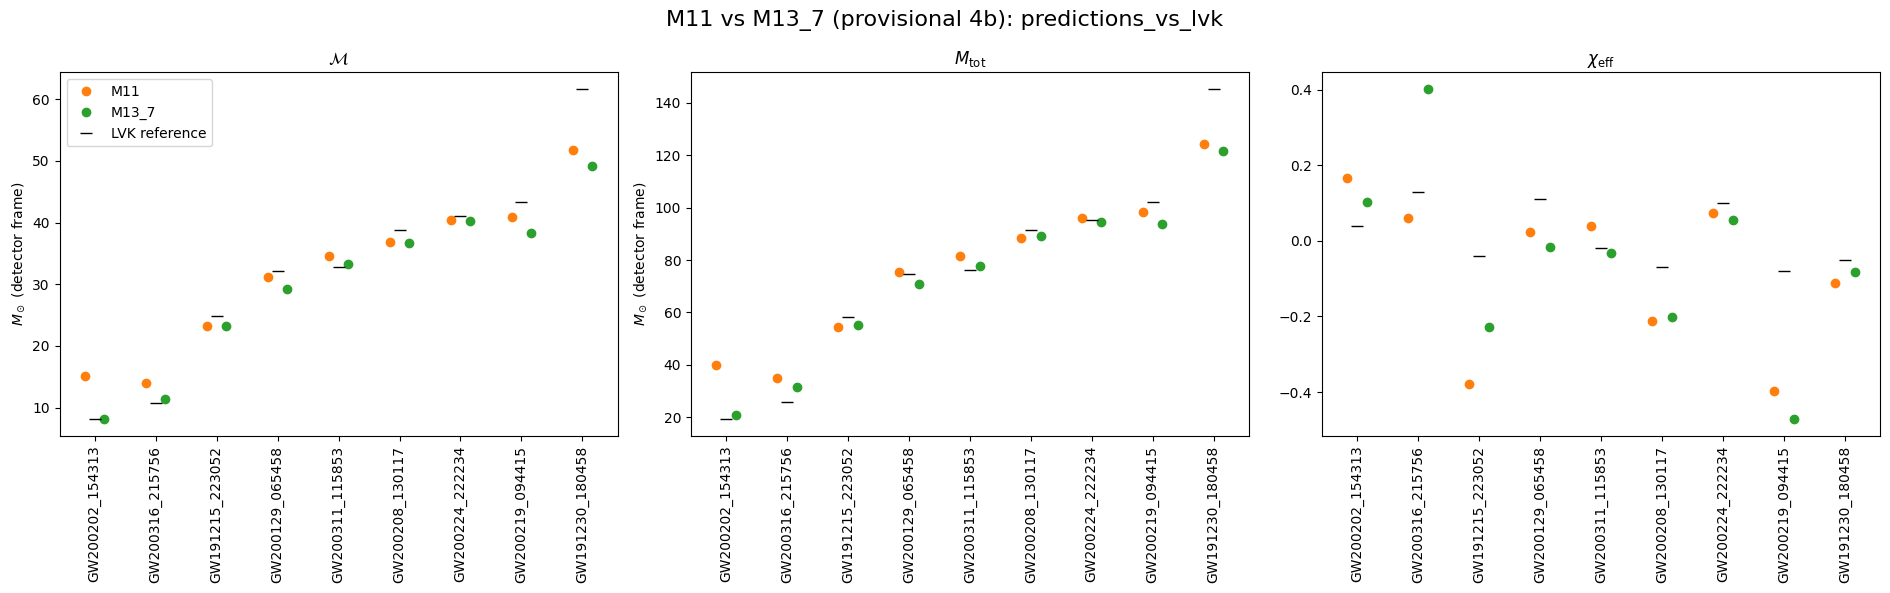

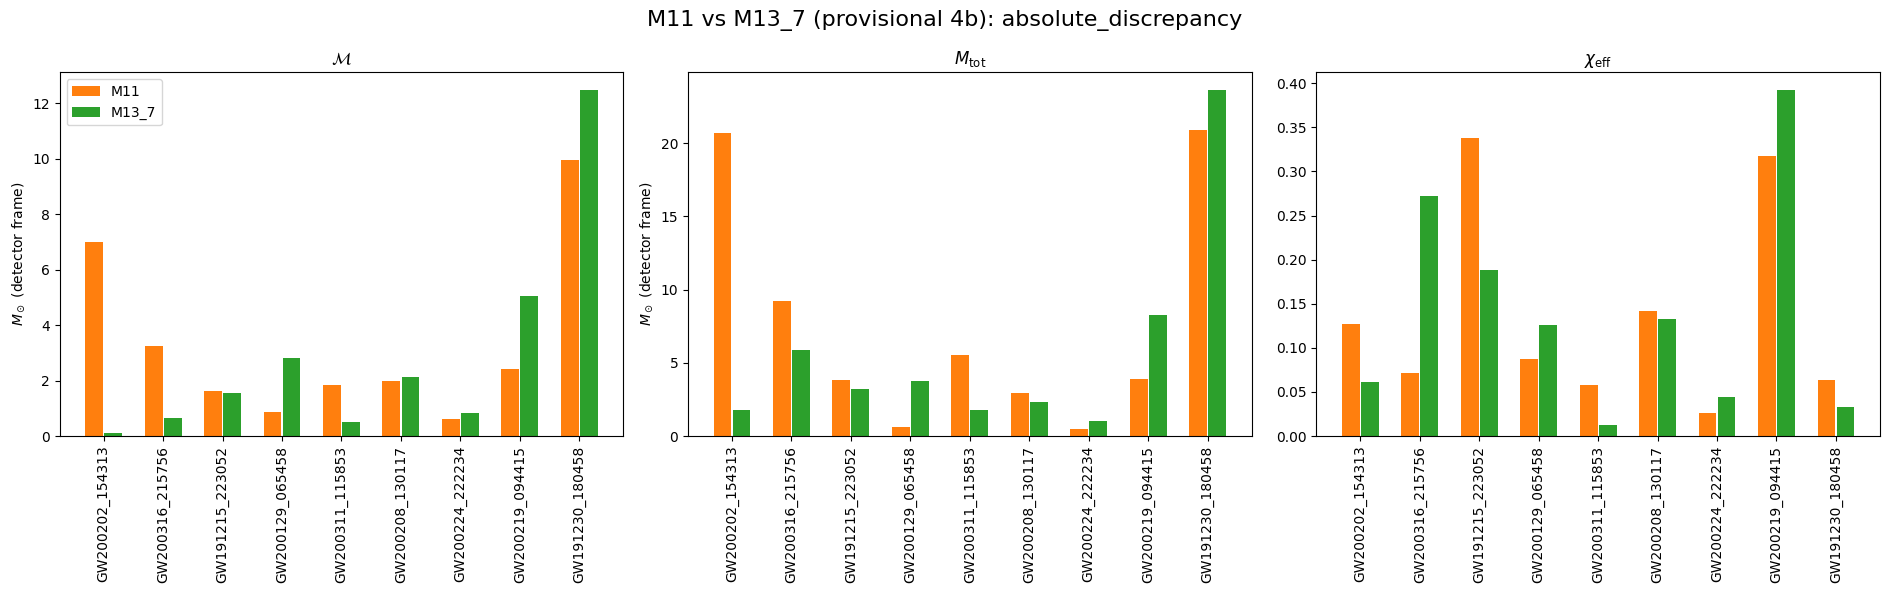

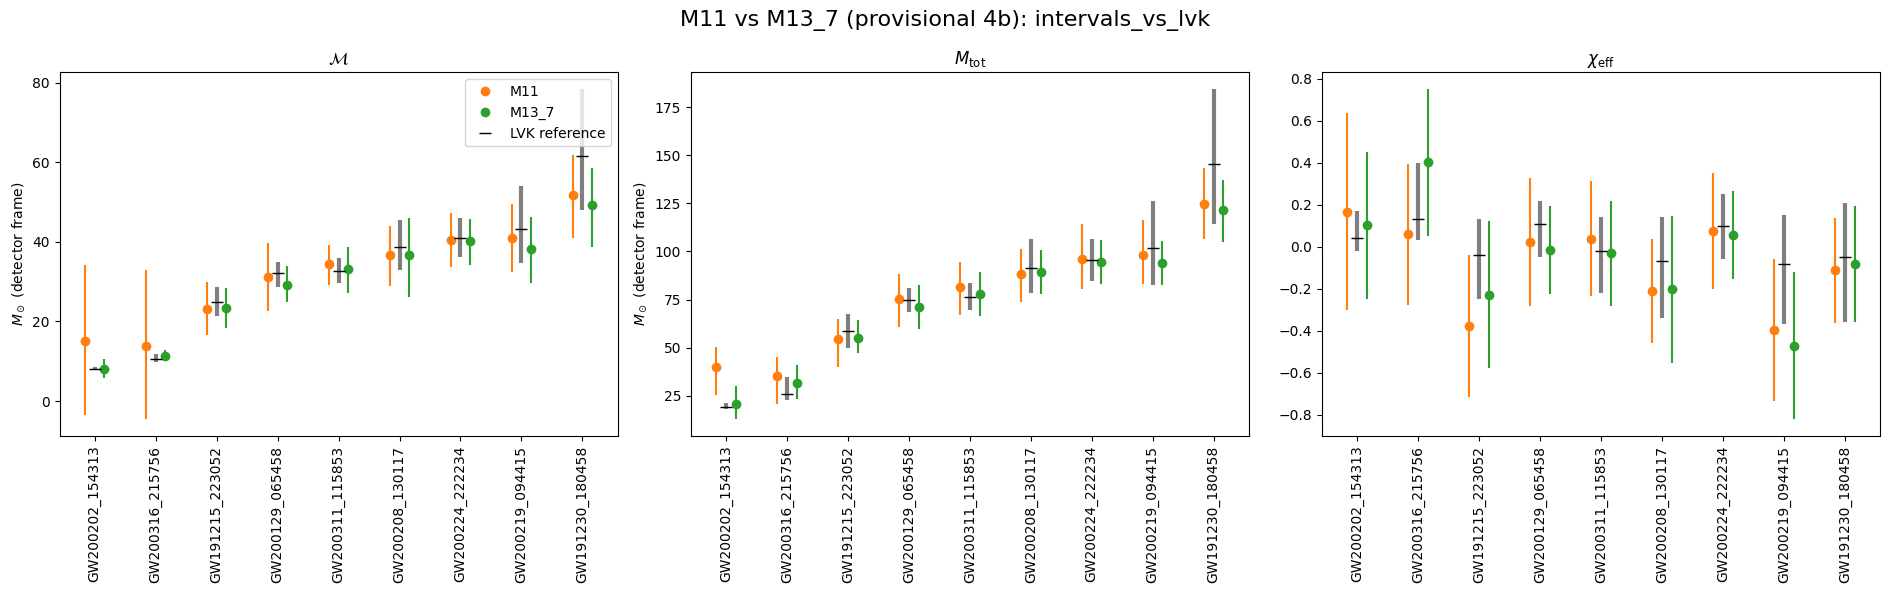

In [15]:
nice_labels = {"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_\mathrm{eff}$"}
if not per_event.empty:
    shifts = {"M11": -.16, "M13_7": .16} if len(MODELS) == 2 else {"M13_7": 0.0}
    colors = {"M11": "C1", "M13_7": "C2"}
    for kind in ("predictions_vs_lvk", "absolute_discrepancy", "intervals_vs_lvk"):
        fig, axes = plt.subplots(1, 3, figsize=(19, 6))
        fig.suptitle(f"{' vs '.join(MODELS)} (provisional 4b): {kind}", fontsize=16)
        for ax, label in zip(axes, LABELS):
            table = per_event[per_event.label == label].reset_index(drop=True)
            x = np.arange(len(table))
            for m in MODELS:
                if kind == "absolute_discrepancy":
                    ax.bar(x + shifts[m], table[f"absolute_discrepancy_{m}"], width=.3, label=m, color=colors[m])
                else:
                    ax.plot(x + shifts[m], table[f"prediction_{m}"], "o", label=m, color=colors[m])
                    if kind == "intervals_vs_lvk":
                        ax.vlines(x + shifts[m], table[f"lower_{m}"], table[f"upper_{m}"], color=colors[m])
            if kind != "absolute_discrepancy":
                ax.plot(x, table.lvk_central, "k_", markersize=9, label="LVK reference")
                if kind == "intervals_vs_lvk":
                    ax.vlines(x, table.lvk_lower, table.lvk_upper, color="black", linewidth=3, alpha=.5)
            ax.set_xticks(x)
            ax.set_xticklabels(table.event, rotation=90)
            ax.set(title=nice_labels[label], ylabel=r"$M_\odot$ (detector frame)" if label != "chi_eff" else "")
        axes[0].legend()
        fig.tight_layout()
        save(fig, f"real_{kind}")

## 6b. E — Posteriores LVK por muestras (GWTC-3 PE v2, Zenodo 8177023)

Ficheros descargados con `scripts/m13/fetch_gwtc3_pe_samples.py` en `<data_root>/external/gwtc3_pe/`: uno por
evento, `IGWN-GWTC3p0-v2-<evento>_PEDataRelease_mixed_cosmo.h5` (muestras combinadas IMRPhenomXPHM +
SEOBNRv4PHM y prior cosmológico; la elección está documentada en el docstring del script). Cada fichero debe
figurar en un `manifest_*.json` de la descarga con el mismo tamaño. **Si no hay ficheros para los eventos
procesados en C, la sección se salta y lo dice**; D registra entonces `null`.

**Claves.** Se espera el análisis `C01:Mixed` con el dataset compuesto `posterior_samples` y los campos `chirp_mass`,
`total_mass` y `chi_eff`. En pesummary, los nombres sin el sufijo `_source` están en el sistema del detector. Si falta
`total_mass`, se usa `mass_1 + mass_2`. Antes de procesar todos los eventos se comprueba uno; si el grupo o los campos no
coinciden, la celda se detiene y muestra las claves disponibles. En cada evento se exige que existan `chirp_mass_source`
y `redshift` y que `chirp_mass = (1+z)·chirp_mass_source` muestra a muestra (con una tolerancia relativa de 1e−6).

**Sistema de las etiquetas.** Nuestras etiquetas están en el sistema del detector: `src/labels.py` las calcula con las mismas
`mass_1` y `mass_2` que recibe el waveform (`src/waveform.py`), sin aplicar redshift. χ_eff se obtiene de los espines alineados,
con la misma definición que LVK.

**Métricas (por evento, política y label; sólo evaluación, aquí no se ajusta ni se elige nada).**
- `pred_quantile_in_lvk`: fracción de muestras LVK ≤ nuestra predicción (0,5 = mediana de LVK).
- `pred_inside_lvk_pe90`: nuestra predicción cae dentro del intervalo 5–95 % de las muestras.
- `lvk_best_inside_mondrian`: el best de GWOSC (la referencia de primer orden de C, en el sistema del detector) cae dentro de nuestro intervalo Mondrian.
- `lvk_pe_width90` (anchura 5–95 % de las muestras) frente a `width` (Mondrian, al nivel nominal de A) y frente a
  `lvk_first_order_width` (la referencia de primer orden de C).

La comparación de primer orden de C se mantiene sin cambios, por continuidad. La posterior de LVK no es la verdad conocida.
Con una cohorte pequeña y seleccionada no se hacen tests estadísticos. En la figura, el punto M11 sale de los resultados
guardados de M11.14 (`lvk_comparison.csv`), sin intervalo recalculado.

In [16]:
PE_DIR = DATA_ROOT / "external/gwtc3_pe"
PE_VARIANT = "mixed_cosmo"
PE_GROUP = "C01:Mixed"  # combined-waveform default analysis of the GWTC-3 release
PE_LEVEL = 0.90
PE_Q = [(1 - PE_LEVEL) / 2, 1 - (1 - PE_LEVEL) / 2]
if NOMINAL != PE_LEVEL:
    print(f"Note: Mondrian nominal level {NOMINAL} differs from the LVK sample interval level {PE_LEVEL}")


def pe_file(event):
    base = re.sub(r"-v\d+$", "", str(event))
    hits = sorted(PE_DIR.glob(f"*{base}_PEDataRelease_{PE_VARIANT}.h5"))
    require(len(hits) <= 1, f"Ambiguous PE files for {event}: {hits}")
    return hits[0] if hits else None


def read_pe_samples(path):
    """LVK samples [chirp_mass, total_mass, chi_eff] in detector frame; stops with available keys on mismatch."""
    with h5py.File(path, "r") as h:
        groups = list(h.keys())
        if PE_GROUP not in h or "posterior_samples" not in h[PE_GROUP]:
            inner = f"; keys in {PE_GROUP}: {list(h[PE_GROUP].keys())}" if PE_GROUP in h else ""
            raise KeyError(f"{path.name}: expected {PE_GROUP}/posterior_samples; top-level keys {groups}{inner}")
        ds = h[PE_GROUP]["posterior_samples"]
        names = ds.dtype.names if isinstance(ds, h5py.Dataset) else None
        if names is None:
            raise KeyError(f"{path.name}: {PE_GROUP}/posterior_samples is not a compound dataset "
                           f"({type(ds).__name__}, keys/dtype: {list(ds.keys()) if isinstance(ds, h5py.Group) else ds.dtype})")
        # No `_source` suffix = detector frame in pesummary; source/redshift only for the frame check.
        mass_fields = ["total_mass"] if "total_mass" in names else ["mass_1", "mass_2"]
        need = ["chirp_mass", *mass_fields, "chi_eff", "chirp_mass_source", "redshift"]
        missing = [n for n in need if n not in names]
        if missing:
            raise KeyError(f"{path.name}: missing {missing} in {PE_GROUP}/posterior_samples; available {sorted(names)}")
        col = {n: np.asarray(ds[n], dtype=float) for n in need}
    total = col["total_mass"] if "total_mass" in col else col["mass_1"] + col["mass_2"]
    samples = np.column_stack([col["chirp_mass"], total, col["chi_eff"]])
    require(np.isfinite(samples).all(), f"{path.name}: non-finite samples")
    frame_dev = float(np.max(np.abs(col["chirp_mass"] / ((1 + col["redshift"]) * col["chirp_mass_source"]) - 1)))
    require(frame_dev < 1e-6, f"{path.name}: chirp_mass != (1+z) chirp_mass_source (max rel {frame_dev:.2e}); STOP")
    info = dict(file=str(path), size=path.stat().st_size, top_level_keys=groups, group=PE_GROUP,
                n_samples=int(len(samples)), total_mass_from="+".join(mass_fields),
                detector_frame_max_rel_dev=frame_dev)
    return samples, info


LVK_PE_SUMMARY = None
pe_events = per_event.event.drop_duplicates().tolist() if not per_event.empty else []
pe_paths = {e: pe_file(e) for e in pe_events} if PE_DIR.is_dir() else {}
PE_AVAILABLE = any(p is not None for p in pe_paths.values())
if not PE_AVAILABLE:
    print(f"Section E skipped: no {PE_VARIANT} files in {PE_DIR} for the events processed in C "
          f"({len(pe_events)}). Run scripts/m13/fetch_gwtc3_pe_samples.py --download first.")
else:
    pe_missing = [e for e, p in pe_paths.items() if p is None]
    print("Events without PE file (excluded from E):", pe_missing)
    # Key check on one event before processing all.
    first = next(e for e in pe_events if pe_paths[e] is not None)
    with h5py.File(pe_paths[first], "r") as h:
        print(first, "top-level keys:", list(h.keys()))
        if PE_GROUP in h:
            print(f"{PE_GROUP} keys:", list(h[PE_GROUP].keys()))
    _, first_info = read_pe_samples(pe_paths[first])
    display(pd.Series(first_info))

Events without PE file (excluded from E): []
GW200202_154313 top-level keys: ['C01:IMRPhenomXPHM', 'C01:Mixed', 'C01:SEOBNRv4PHM', 'history', 'version']
C01:Mixed keys: ['approximant', 'calibration_envelope', 'config_file', 'description', 'injection_data', 'meta_data', 'posterior_samples', 'priors', 'psds', 'version']


file                          /data/vserrano/cbc_pe_data/external/gwtc3_pe/I...
size                                                                  336376074
top_level_keys                [C01:IMRPhenomXPHM, C01:Mixed, C01:SEOBNRv4PHM...
group                                                                 C01:Mixed
n_samples                                                                 43480
total_mass_from                                                      total_mass
detector_frame_max_rel_dev                                                  0.0
dtype: object

### Tabla por evento y agregado (cuantil, best en Mondrian, anchuras 90 %)

In [17]:
pe_table, pe_aggregate, pe_samples, pe_info = pd.DataFrame(), pd.DataFrame(), {}, {}
if PE_AVAILABLE:
    manifest_files = {f["key"]: f for m in sorted(PE_DIR.glob("manifest_*.json")) for f in read_json(m)["files"]}
    for event in pe_events:
        path = pe_paths[event]
        if path is None:
            continue
        samples, info = read_pe_samples(path)
        entry = manifest_files.get(path.name)
        require(entry is not None and entry["size"] == info["size"],
                f"{path.name}: absent from download manifests or size differs")
        info["md5_zenodo"] = entry["md5"]
        pe_samples[event], pe_info[event] = samples, info
    rows = []
    for r in comparisons[comparisons.event.isin(pe_samples)].itertuples(index=False):
        s = pe_samples[r.event][:, LABELS.index(r.label)]
        lo, hi = np.quantile(s, PE_Q)
        rows.append(dict(event=r.event, policy=r.policy, label=r.label, prediction=r.prediction,
            lower=r.lower, upper=r.upper, width=r.width, lvk_best=r.lvk_central,
            lvk_first_order_lower=r.lvk_lower, lvk_first_order_upper=r.lvk_upper,
            lvk_first_order_width=r.lvk_upper - r.lvk_lower, lvk_pe_median=float(np.median(s)),
            lvk_pe_lower90=float(lo), lvk_pe_upper90=float(hi), lvk_pe_width90=float(hi - lo),
            pred_quantile_in_lvk=float(np.mean(s <= r.prediction)),
            pred_inside_lvk_pe90=bool(lo <= r.prediction <= hi),
            lvk_best_inside_mondrian=bool(r.lower <= r.lvk_central <= r.upper),
            width_ratio_mondrian_over_lvk_pe90=float(r.width / (hi - lo)), n_samples=len(s)))
    pe_table = pd.DataFrame(rows)
    pe_aggregate = (pe_table.groupby(["policy", "label"], sort=False)
                    .agg(n_events=("event", "size"),
                         median_pred_quantile_in_lvk=("pred_quantile_in_lvk", "median"),
                         fraction_pred_inside_lvk_pe90=("pred_inside_lvk_pe90", "mean"),
                         fraction_lvk_best_inside_mondrian=("lvk_best_inside_mondrian", "mean"),
                         median_width_mondrian=("width", "median"),
                         median_lvk_pe_width90=("lvk_pe_width90", "median"),
                         median_lvk_first_order_width=("lvk_first_order_width", "median"),
                         median_width_ratio_mondrian_over_lvk_pe90=("width_ratio_mondrian_over_lvk_pe90", "median"))
                    .reset_index())
    display(pe_aggregate)
    display(pe_table[pe_table.policy == PRIMARY_POLICY])
    pe_table.to_csv(OUTPUT_DIR / "real_lvk_pe_comparison.csv", index=False)
    pe_aggregate.to_csv(OUTPUT_DIR / "real_lvk_pe_aggregate.csv", index=False)
    LVK_PE_SUMMARY = dict(source="Zenodo 8177023 (GWTC-3 PE, v2)", variant=PE_VARIANT, group=PE_GROUP,
        level=PE_LEVEL, directory=str(PE_DIR), events_without_file=pe_missing, files=pe_info,
        per_event=pe_table.to_dict("records"), aggregate=pe_aggregate.to_dict("records"))

,policy,label,n_events,median_pred_quantile_in_lvk,fraction_pred_inside_lvk_pe90,fraction_lvk_best_inside_mondrian,median_width_mondrian,median_lvk_pe_width90,median_lvk_first_order_width,median_width_ratio_mondrian_over_lvk_pe90
0,conservative,chirp_mass,9,0.069963,0.444444,0.888889,11.457421,5.424643,7.263515,2.008794
1,efficient,chirp_mass,9,0.069963,0.444444,0.888889,10.933112,5.424643,7.263515,2.181581
2,conservative,total_mass,9,0.351846,0.888889,0.888889,22.824977,11.822186,17.497031,1.777398
3,efficient,total_mass,9,0.351846,0.888889,0.888889,22.824977,11.822186,17.497031,1.777398
4,conservative,chi_eff,9,0.320098,0.777778,0.888889,0.701529,0.370021,0.370000,1.450894
5,efficient,chi_eff,9,0.320098,0.777778,0.888889,0.656690,0.370021,0.370000,1.475161


,event,policy,label,prediction,lower,upper,width,lvk_best,lvk_first_order_lower,lvk_first_order_upper,lvk_first_order_width,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,lvk_pe_width90,pred_quantile_in_lvk,pred_inside_lvk_pe90,lvk_best_inside_mondrian,width_ratio_mondrian_over_lvk_pe90,n_samples
0,GW200202_154313,conservative,chirp_mass,8.057928,5.831881,10.576809,4.744928,8.1641,7.851028,8.508955,0.657927,8.148216,8.100908,8.197289,0.096380,0.001702,False,True,49.231212,43480
2,GW200202_154313,conservative,total_mass,20.916944,12.694291,30.218680,17.524389,19.1622,18.261373,21.172804,2.911430,19.014045,18.671932,21.007063,2.335131,0.945607,True,True,7.504671,43480
4,GW200202_154313,conservative,chi_eff,0.101240,-0.249524,0.452004,0.701529,0.0400,-0.020000,0.170000,0.190000,0.039397,-0.017925,0.165387,0.183311,0.838730,True,True,3.826979,43480
6,GW200316_215756,conservative,chirp_mass,11.326364,9.952372,12.747449,2.795077,10.6750,9.705340,11.705602,2.000262,10.676260,10.560722,10.791383,0.230661,1.000000,False,True,12.117669,129267
8,GW200316_215756,conservative,total_mass,31.730568,23.507915,41.032304,17.524389,25.8640,22.892466,34.810232,11.917767,25.516781,24.429174,34.288747,9.859573,0.912623,True,True,1.777398,129267
10,GW200316_215756,conservative,chi_eff,0.401710,0.050945,0.752474,0.701529,0.1300,0.030000,0.400000,0.370000,0.126015,0.024449,0.394471,0.370021,0.954087,False,True,1.895915,129267
12,GW191215_223052,conservative,chirp_mass,23.299082,18.280630,28.482754,10.202124,24.8400,21.389956,28.653471,7.263515,24.867089,23.418037,26.336238,2.918200,0.038384,False,True,3.496033,8884
14,GW191215_223052,conservative,total_mass,55.228054,47.005401,64.529790,17.524389,58.4550,50.061796,67.558827,17.497031,58.414994,54.757871,63.223302,8.465431,0.079244,True,True,2.070112,8884
16,GW191215_223052,conservative,chi_eff,-0.227932,-0.578696,0.122833,0.701529,-0.0400,-0.250000,0.130000,0.380000,-0.041186,-0.249205,0.127465,0.376670,0.068888,True,True,1.862449,8884
18,GW200129_065458,conservative,chirp_mass,29.283779,25.002960,33.876593,8.873633,32.0960,28.780730,34.922674,6.141943,32.063561,29.426513,33.843905,4.417392,0.045158,False,True,2.008794,1993


### Figuras: violin de la posterior LVK por evento (una figura por label, conservative)

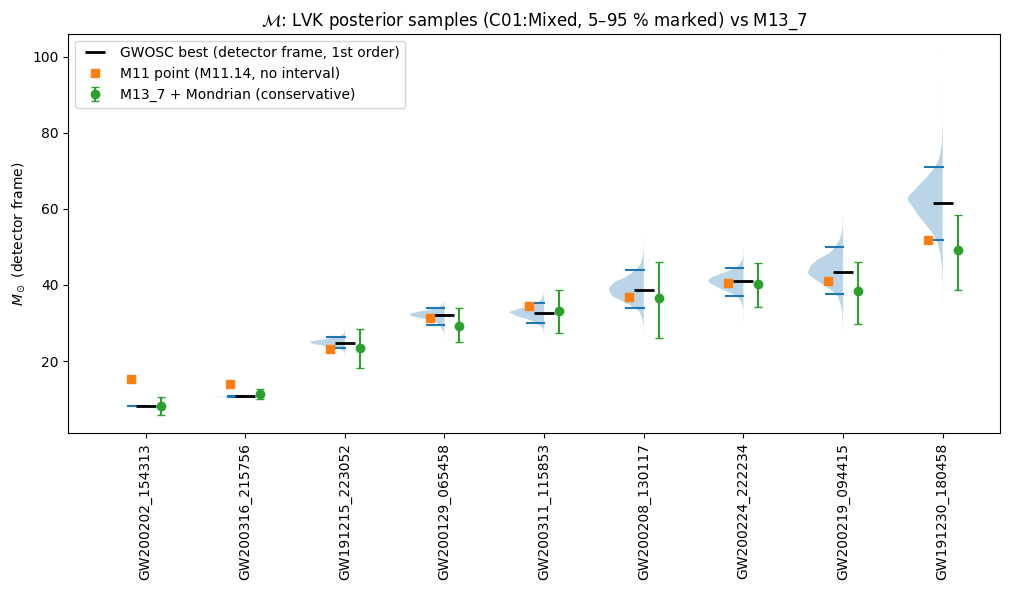

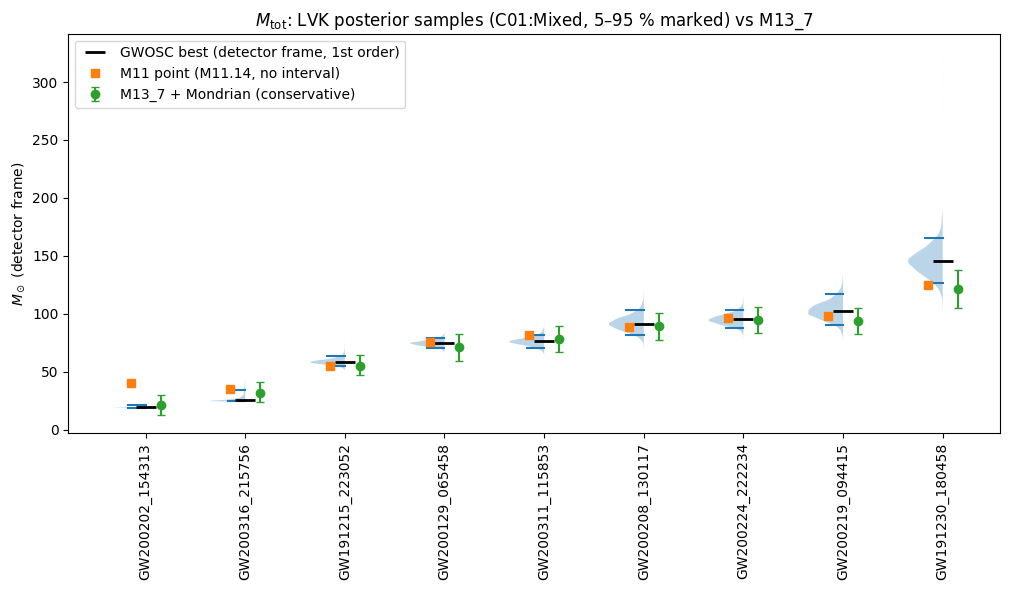

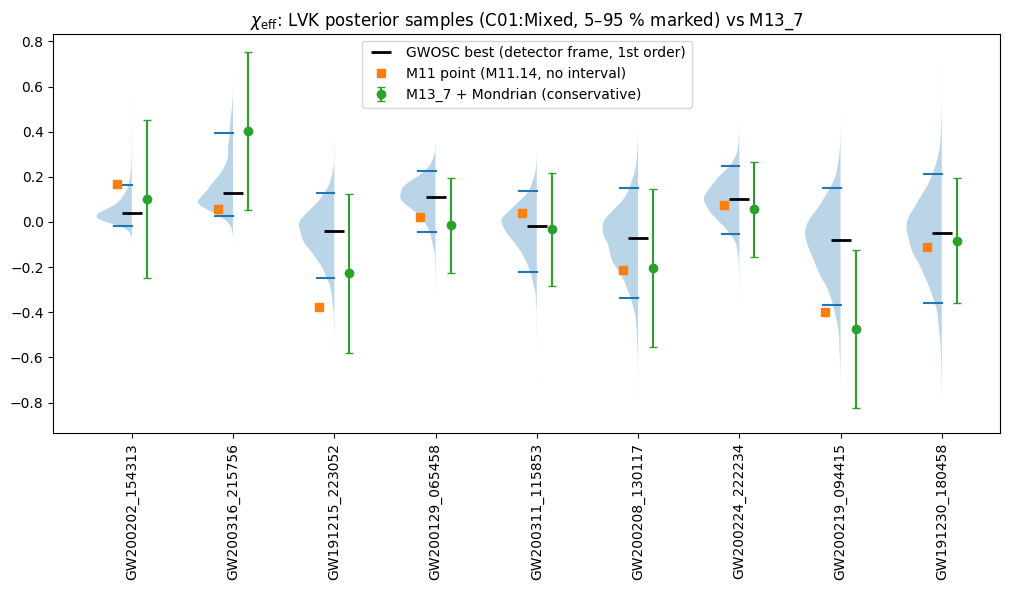

In [20]:
if not pe_table.empty:
    main_pe = pe_table[pe_table.policy == PRIMARY_POLICY]
    for label in LABELS:
        table = main_pe[main_pe.label == label].reset_index(drop=True)
        x, j = np.arange(len(table)), LABELS.index(label)
        fig, ax = plt.subplots(figsize=(max(8, .8 * len(table) + 3), 6))
        ax.violinplot([pe_samples[e][:, j] for e in table.event], positions=x, widths=.7,
                      showextrema=False, quantiles=[PE_Q] * len(table), side='low')
        ax.plot(x, table.lvk_best, "k_", markersize=14, mew=2, label="GWOSC best (detector frame, 1st order)")
        yerr = np.clip([table.prediction - table.lower, table.upper - table.prediction], 0, None)
        ax.errorbar(x + .15, table.prediction, yerr=yerr, fmt="o", color="C2", capsize=3,
                    label=f"M13_7 + Mondrian ({PRIMARY_POLICY})")
        if "prediction_M11" in per_event:
            m11 = per_event[per_event.label == label].set_index("event").prediction_M11.reindex(table.event)
            ax.plot(x - .15, m11.to_numpy(), "s", color="C1", label="M11 point (M11.14, no interval)")
        ax.set_xticks(x)
        ax.set_xticklabels(table.event, rotation=90)
        ax.set(title=f"{nice_labels[label]}: LVK posterior samples ({PE_GROUP}, 5–95 % marked) vs M13_7",
               ylabel=r"$M_\odot$ (detector frame)" if label != "chi_eff" else "")
        ax.legend()
        fig.tight_layout()
        save(fig, f"real_lvk_pe_violin_{label}")

## 7. D — Resumen JSON con sello temporal

Se escribe en modo `'x'`, así que nunca sobrescribe. Recoge los roles de los splits, la procedencia
(hashes de ficheros pequeños y del checkpoint, el bundle y las predicciones), el método Mondrian heredado,
los resultados de test con el criterio, el contrato de procesado real, el estado de cada evento y
la comparación con las muestras LVK de E (`lvk_posterior_samples`; `null` si E se saltó).

In [19]:
SUMMARY_PATH = OUTPUT_DIR / f"M13_7_summary_{RUN_STAMP}.json"
summary = dict(
    created_utc=datetime.now(timezone.utc).isoformat(), run_stamp=RUN_STAMP, model=TAG, provisional=True,
    data_roles=dict(fit="cal (Mondrian quantiles only)", method_selection="inherited from M11 selection on val",
        test="evaluation only of a provisional model; nothing fitted or selected on test",
        real_events="evaluation only; test and real events do not enter model choice"),
    provenance=dict(checkpoint=str(CHECKPOINT), checkpoint_sha256=file_sha256(CHECKPOINT),
        predictions=str(PREDICTIONS_PATH), predictions_sha256=file_sha256(PREDICTIONS_PATH),
        split=str(SPLIT_PATH), g3_hdf5=str(G3_H5), train_config=str(TRAIN_CFG_PATH),
        prediction_config=str(PRED_CFG_PATH), generation_config=str(GEN_M13_PATH),
        m11_selection=str(M11_SELECTION), m11_bundle_manifest=str(M11_BUNDLE_MANIFEST),
        bundle=str(BUNDLE_PATH), bundle_sha256=BUNDLE_SHA256,
        notebook=str(PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"),
        cohort=str(EVENT_LIST_PATH), cohort_sha256=file_sha256(EVENT_LIST_PATH),
        lvk=str(LVK_PATH), lvk_sha256=file_sha256(LVK_PATH),
        versions=dict(python=sys.version, numpy=np.__version__, torch=torch.__version__)),
    mondrian=dict(hyperparameters=HP, systems=selected[["final_policy", "label", "taxonomy_mode",
        "interval_mode", "n_bins"]].to_dict("records")),
    test=dict(criterion=dict(abs_coverage_gap_max=COVERAGE_TOLERANCE, per_bin_min_n=MIN_BIN_N_FOR_CRITERION,
                             nominal=NOMINAL, note="operational threshold, not a statistical test"),
              summary=test_summary.to_dict("records"),
              width_vs_M11_descriptive=None if width_comparison is None else width_comparison.to_dict("records"),
              fixed_examples=dict(seed=EXAMPLE_SEED, n=N_EXAMPLES)),
    real_events=dict(processing=processing_contract,
        m11_difference="M11.14 conditioned the PSD twice (0.5 s estimation + 0.5 s processor); accepted, not measured",
        status=events[["event", "processing_status", "historical_failure"]].to_dict("records"),
        skipped=skipped_rows, processed=processed_provenance,
        aggregate=aggregate_summary.to_dict("records"), primary_policy=PRIMARY_POLICY,
        lvk_posterior_samples=LVK_PE_SUMMARY),
)
with SUMMARY_PATH.open("x", encoding="utf-8") as f:
    # numpy scalars -> Python scalars; anything else as text.
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Summary:", SUMMARY_PATH)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/M13_7_summary_20261102T164134Z.json


## 8. Resumen — completar sólo con resultados tras ejecutar

| Label | Cobertura test marginal (cons./eff.) | Bins n≥500 dentro de ±2 pt | Anchura media vs M11 | Eventos reales: discrepancia mediana (M13.7 / M11) |
|---|---|---|---|---|
| chirp_mass | 0,900 / 0,898 | 15/16 / 37/48 (FALLA el criterio; nº de fallos ≈ el esperado por ruido de cal+test: 0,7 y 11,5) | 0,80× | 1,54 / 1,99 |
| total_mass | 0,904 / 0,904 | 4/4 / 4/4 | 0,84× | 3,23 / 3,87 |
| chi_eff | 0,903 / 0,905 | 8/8 / 4/4 | 0,83× | 0,125 / 0,087 |

- El criterio de ±2 puntos por bin no tenía en cuenta el ruido finito de cal y test; para bins de ~600 filas la desviación de la cobertura es ~1,7 puntos. Próximo criterio: binomial, con el ruido de cal incluido.
- Posteriores LVK: la propagación a primer orden sobreestima la anchura de LVK en masas (chirp 7,3 frente a 5,4; total 17,5 frente a 11,8); nuestros intervalos son ~2,0× / 1,8× / 1,45× la anchura del 90 % de LVK.
- Hipótesis: sesgo a la baja de la chirp mass en eventos reales (7/9; cuantil mediano 0,07); n = 9, sin test.